# Synthetic IP Shock Diagnostics

This notebook is an OpenGGCM analysis template for interplanetary (IP) shocks.

You may change `RUN_NAME` in the configuration cell below for reuse.

In [1]:
import pathlib
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from ggcmpy import plot_polar
from ggcmpy.timeseries import store_to_pyspedas
from matplotlib import colors
from pyspedas import options, store_data, timebar, tplot

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

In [2]:
# Run configuration
RUN_NAME = "261121_0007"
RUNS_ROOT = pathlib.Path("/mnt/home/germaschewski/cu1010/runs")
RUN_DIR = RUNS_ROOT / RUN_NAME
DATA_DIR = RUN_DIR / "target"
PLOTS_DIR = RUN_DIR / "plots"

# Analysis windows [minutes since STARTTIME]
NOMINAL_SHOCK_MIN = 90.0  # Refined automatically from swdata density jump
SHOCK_WINDOW_MIN = (80.0, 140.0)  # Focused shock-response window
TIME_SLICE_MIN = (
    None  # None: use all available output, or select a window, e.g., (0.0, 180.0).
)

# Save a compact per-run metrics CSV for cross-run comparison.
EXPORT_METRICS_CSV = True

# Video frame export. Keep False during interactive runs.
GENERATE_VIDEO_FRAMES = True
VIDEO_IONO_WINDOW_MIN = (
    80.0,
    150.0,
)  # None: full run; tuple: [t_min0, t_min1] around shock
VIDEO_IONO_STRIDE = 1  # 1: full 6 s cadence, 5: 30 s, 10: 60 s

In [3]:
# Parse run metadata from runme and check the log health.
SHOCK_CATALOG = {
    "S00_F180": (180.0, np.nan, "Frontal Head-On"),
    "S01_165_C000": (165.0, 0.0, "Nearly Frontal (UPT, Dawn-first)"),
    "S02_165_C180": (165.0, 180.0, "Nearly Frontal (UPT, Dusk-first)"),
    "S03_165_C270": (165.0, 270.0, "Nearly Frontal (UPT, NH-first)"),
    "S04_165_C315": (165.0, 315.0, "Nearly Frontal (UPT, Diagonal Dawn+NH-first)"),
    "S05_150_C000": (150.0, 0.0, "Mod. Inclined (Median, Dawn-first)"),
    "S06_150_C180": (150.0, 180.0, "Mod. Inclined (Median, Dusk-first)"),
    "S07_150_C270": (150.0, 270.0, "Mod. Inclined (Median, NH-first)"),
    "S08_150_C315": (150.0, 315.0, "Mod. Inclined (Median, Diagonal Dawn+NH-first)"),
    "S09_135_C000": (135.0, 0.0, "Highly Inclined (LPT, Dawn-first)"),
    "S10_135_C180": (135.0, 180.0, "Highly Inclined (LPT, Dusk-first)"),
    "S11_135_C270": (135.0, 270.0, "Highly Inclined (LPT, NH-first)"),
    "S12_135_C315": (135.0, 315.0, "Highly Inclined (LPT, Diagonal Dawn+NH-first)"),
}


def parse_runme(runme_path: pathlib.Path) -> dict[str, str]:
    params: dict[str, str] = {}
    if not runme_path.exists():
        return params
    keys = {
        "STARTTIME",
        "ENDTIME",
        "DIPOLTIME",
        "CTIM",
        "SWFILE",
        "IONODT",
        "OUTTIMEIO",
        "SIG_FLOOR",
        "ALPHAFAK",
        "DO_LIMIT3",
    }
    for line in runme_path.read_text().splitlines():
        s = line.split("#", 1)[0].strip()
        if not s:
            continue
        parts = s.split(None, 1)
        if len(parts) == 2 and parts[0] in keys:
            params[parts[0]] = parts[1].strip()
    return params


def parse_ggcm_time(ts: str) -> pd.Timestamp:
    return pd.to_datetime(ts, format="%Y:%m:%d:%H:%M:%S.%f")


def infer_conductance_model(ctim_val: str) -> str:
    v = ctim_val.lower()
    if v in ("none", "sigaa2", "srv-sigaa2"):
        return f"Robinson ({ctim_val})"
    if v == "ext":
        return "GITM (ext)"
    return f"CTIM ({ctim_val})"


def normalize_shock_key(swfile: str) -> str:
    stem = pathlib.Path(swfile).name.removeprefix("swdata_")
    m = re.match(r"S(\d+)_(.+)$", stem)
    if m:
        idx = int(m.group(1))
        rest = m.group(2)
        m2 = re.match(r"(\d+)_C(\d+)$", rest)
        if m2:
            return f"S{idx:02d}_{m2.group(1)}_C{int(m2.group(2)):03d}"
        return f"S{idx:02d}_{rest}"
    return stem


runme_cfg = parse_runme(RUN_DIR / "runme")
START_TIME = (
    parse_ggcm_time(runme_cfg["STARTTIME"]) if "STARTTIME" in runme_cfg else None
)
END_TIME = parse_ggcm_time(runme_cfg["ENDTIME"]) if "ENDTIME" in runme_cfg else None
DIPOL_TIME = runme_cfg.get("DIPOLTIME", "unknown")
CONDUCTANCE_MODEL = infer_conductance_model(runme_cfg.get("CTIM", "unknown"))
SWFILE_RAW = runme_cfg.get("SWFILE", "")
SHOCK_ID = normalize_shock_key(SWFILE_RAW) if SWFILE_RAW else "unknown"
THETA_XN, PHI_YN, SHOCK_DESC = SHOCK_CATALOG.get(
    SHOCK_ID, (np.nan, np.nan, "Custom / Uncataloged")
)
if np.isfinite(THETA_XN) and np.isfinite(PHI_YN):
    RUN_LABEL = (
        f"{RUN_NAME}, {SHOCK_ID} ($\\theta_{{xn}}={THETA_XN:.0f}^\\circ$, "
        f"$\\varphi_{{yn}}={PHI_YN:.0f}^\\circ$), {CONDUCTANCE_MODEL}"
    )
elif np.isfinite(THETA_XN):
    RUN_LABEL = f"{RUN_NAME}, {SHOCK_ID} ($\\theta_{{xn}}={THETA_XN:.0f}^\\circ$), {CONDUCTANCE_MODEL}"
else:
    RUN_LABEL = f"{RUN_NAME}, {SHOCK_ID}, {CONDUCTANCE_MODEL}"

# Check output file counts and scan logs for numerical health warnings.
file_counts = {
    ext: len(list(DATA_DIR.glob(f"{RUN_NAME}.{ext}.*")))
    for ext in ("iof", "py_0", "pz_0", "px_0", "ioc")
}

n_iochk1 = 0
n_nan_log = 0
last_ti_line = ""
for log_path in [DATA_DIR / f"{RUN_NAME}.log", *sorted(DATA_DIR.glob("slurm-*.out"))]:
    if not log_path.exists():
        continue
    text = log_path.read_text(errors="ignore")
    n_iochk1 += text.count("iochk1")
    n_nan_log += len(re.findall(r"\bNaN\b", text))
    for line in reversed(text.splitlines()):
        if "ti=" in line and "dt=" in line:
            last_ti_line = line.strip()
            break

phi_str = f"{PHI_YN:.1f} deg" if np.isfinite(PHI_YN) else "--"
print(f"Run ID: {RUN_NAME}")
print(f"Shock: {SHOCK_ID} — {SHOCK_DESC} (theta_xn={THETA_XN} deg, phi_yn={phi_str})")
print(f"Conductance model: {CONDUCTANCE_MODEL}")
print(f"OUTTIMEIO: {runme_cfg.get('OUTTIMEIO', '?')} s")
print(f"STARTTIME: {START_TIME}")
print(f"ENDTIME: {END_TIME}")
print(f"DIPOLTIME: {DIPOL_TIME}")
print(f"SWFILE: {SWFILE_RAW}")
print(f"IONODT: {runme_cfg.get('IONODT', '?')} s")
print(f"SIG_FLOOR: {runme_cfg.get('SIG_FLOOR', 'default')}")
print(f"Available files: {file_counts}")
print(f"Log health: iochk1 clamps = {n_iochk1}, NaN hits = {n_nan_log}")
if last_ti_line:
    print(f"Latest log step: {last_ti_line}")

Run ID: 261121_0007
Shock: S07_150_C270 — Mod. Inclined (Median, NH-first) (theta_xn=150.0 deg, phi_yn=270.0 deg)
Conductance model: CTIM (1.0.10)
OUTTIMEIO: -6 s
STARTTIME: 2000-09-21 00:00:00
ENDTIME: 2000-09-21 03:00:00
DIPOLTIME: 1967:01:01:00:00:00.000
SWFILE: /mnt/home/germaschewski/cu1010/swdata/swdata_S07_150_C270
IONODT: 6.0 s
SIG_FLOOR: 1.5
Available files: {'iof': 1799, 'py_0': 179, 'pz_0': 179, 'px_0': 179, 'ioc': 180}
Log health: iochk1 clamps = 0, NaN hits = 0
Latest log step: cp=   0.253 st=  97998 ti= 10800.000 dt=     0.086


## 1. Synthetic Solar Wind & Interplanetary Shock Input

Reads the OpenGGCM parameters (`SWFILE`, fallback `tmp.swdata1` / `swdata`), verifies the Rankine–Hugoniot jump conditions across the shock ramp, and registers solar-wind variables into `pyspedas` for joint plotting with the geomagnetic indices

In [4]:
# OpenGGCM normalization constants (ggcm_mhd_ggcm.c)
M_AMU = 1.6605655e-27  # kg

# Locate the solar wind input file.
sw_candidates = [
    pathlib.Path(SWFILE_RAW)
    if SWFILE_RAW and SWFILE_RAW not in ("auto", "minvar")
    else None,
    RUN_DIR / "tmp.swdata1",
    RUN_DIR / "swdata",
]
SW_PATH = next((p for p in sw_candidates if p is not None and p.exists()), None)
if SW_PATH is None:
    raise FileNotFoundError(f"Could not find swdata file among {sw_candidates}")

sw_cols = [
    "t_min",
    "bx",
    "by",
    "bz",
    "vx",
    "vy",
    "vz",
    "rr",
    "pp",
    "nx_sw",
    "ny_sw",
    "nz_sw",
]
sw_df = pd.read_csv(SW_PATH, sep=r"\s+", names=sw_cols, comment="#")

# Derived solar-wind quantities (GSE)
sw_df["btot"] = np.sqrt(sw_df["bx"] ** 2 + sw_df["by"] ** 2 + sw_df["bz"] ** 2)
sw_df["vtot"] = np.sqrt(sw_df["vx"] ** 2 + sw_df["vy"] ** 2 + sw_df["vz"] ** 2)
sw_df["pdyn"] = sw_df["rr"] * 1e6 * M_AMU * (sw_df["vtot"] * 1e3) ** 2 * 1e9  # nPa
sw_df["ey"] = (sw_df["vx"] * sw_df["bz"] - sw_df["vz"] * sw_df["bx"]) * 1e-3  # mV/m

# Auto-detect the shock arrival time (density midpoint).
n_pre = sw_df.loc[sw_df["t_min"].between(10.0, 80.0), "rr"].median()
n_post = sw_df.loc[sw_df["t_min"].between(100.0, 170.0), "rr"].median()
if np.isfinite(n_pre) and np.isfinite(n_post) and abs(n_post - n_pre) > 0.5:
    n_mid = 0.5 * (n_pre + n_post)
    cross_idx = (sw_df["rr"] - n_mid).abs().idxmin()
    SHOCK_TIME_MIN = float(sw_df.loc[cross_idx, "t_min"])
else:
    SHOCK_TIME_MIN = NOMINAL_SHOCK_MIN

# Attach UTC timestamps.
if START_TIME is None:
    first_iof = sorted(DATA_DIR.glob(f"{RUN_NAME}.iof.*"))[0]
    with xr.open_dataset(first_iof) as _ds0:
        START_TIME = pd.Timestamp(_ds0.time.values[0]).floor("min")
if END_TIME is None:
    END_TIME = START_TIME + pd.Timedelta(hours=3)

sw_df["time"] = START_TIME + pd.to_timedelta(sw_df["t_min"], unit="m")
sw_df = sw_df.set_index("time")
SHOCK_TIME_TS = START_TIME + pd.Timedelta(minutes=SHOCK_TIME_MIN)

# Upstream and downstream summary
up = sw_df.loc[
    sw_df["t_min"].between(SHOCK_TIME_MIN - 16.0, SHOCK_TIME_MIN - 2.0)
].mean()
dn = sw_df.loc[
    sw_df["t_min"].between(SHOCK_TIME_MIN + 2.0, SHOCK_TIME_MIN + 16.0)
].mean()
sw_summary = pd.DataFrame(
    {
        "Upstream (State 1)": [
            up["rr"],
            up["pp"],
            up["pdyn"],
            up["vx"],
            up["vy"],
            up["vz"],
            up["bx"],
            up["by"],
            up["bz"],
            up["btot"],
            up["ey"],
        ],
        "Downstream (State 2)": [
            dn["rr"],
            dn["pp"],
            dn["pdyn"],
            dn["vx"],
            dn["vy"],
            dn["vz"],
            dn["bx"],
            dn["by"],
            dn["bz"],
            dn["btot"],
            dn["ey"],
        ],
    },
    index=[
        "n [cm^-3]",
        "P_th [pPa]",
        "P_dyn [nPa]",
        "Vx [km/s]",
        "Vy [km/s]",
        "Vz [km/s]",
        "Bx [nT]",
        "By [nT]",
        "Bz [nT]",
        "|B| [nT]",
        "Ey [mV/m]",
    ],
)
sw_summary["Ratio (State 2 / State 1)"] = np.where(
    np.abs(sw_summary["Upstream (State 1)"]) > 1e-6,
    sw_summary["Downstream (State 2)"] / sw_summary["Upstream (State 1)"],
    np.nan,
)

print(f"Loaded SW input: {SW_PATH} ({len(sw_df)} rows)")
print(f"Detected inflow shock arrival: t = {SHOCK_TIME_MIN:.2f} min ({SHOCK_TIME_TS})")
display(sw_summary.round(3))

# Clip the solar wind to the simulation window and store it in pyspedas.
sw_sim = sw_df.loc[START_TIME:END_TIME]
sw_tplot_meta = {
    "sw_bx": ("bx", "IMF Bx", "nT"),
    "sw_by": ("by", "IMF By", "nT"),
    "sw_bz": ("bz", "IMF Bz", "nT"),
    "sw_vx": ("vx", "SW Vx", "km/s"),
    "sw_vy": ("vy", "SW Vy", "km/s"),
    "sw_vz": ("vz", "SW Vz", "km/s"),
    "sw_n": ("rr", "SW Density", "cm^-3"),
    "sw_p": ("pp", "SW Pressure", "pPa"),
    "sw_pdyn": ("pdyn", "SW P_dyn", "nPa"),
    "sw_ey": ("ey", "SW Ey", "mV/m"),
}
sw_times_epoch = sw_sim.index.to_numpy()
for tp_name, (col, label, unit) in sw_tplot_meta.items():
    store_data(tp_name, data={"x": sw_times_epoch, "y": sw_sim[col].to_numpy()})
    options(tp_name, "ytitle", label)
    options(tp_name, "ysubtitle", f"[{unit}]")
    options(tp_name, "legend_names", [label])

Loaded SW input: /mnt/home/germaschewski/cu1010/swdata/swdata_S07_150_C270 (415 rows)
Detected inflow shock arrival: t = 90.00 min (2000-09-21 01:30:00)


,Upstream (State 1),Downstream (State 2),Ratio (State 2 / State 1)
n [cm^-3],5.000,13.100,2.620
P_th [pPa],12.000,108.230,9.019
P_dyn [nPa],1.328,5.368,4.041
Vx [km/s],-400.000,-494.940,1.237
Vy [km/s],0.000,0.000,NaN
Vz [km/s],0.000,-42.530,NaN
Bx [nT],0.000,3.720,NaN
By [nT],0.000,0.000,NaN
Bz [nT],-5.000,-11.440,2.288
|B| [nT],5.000,12.030,2.406


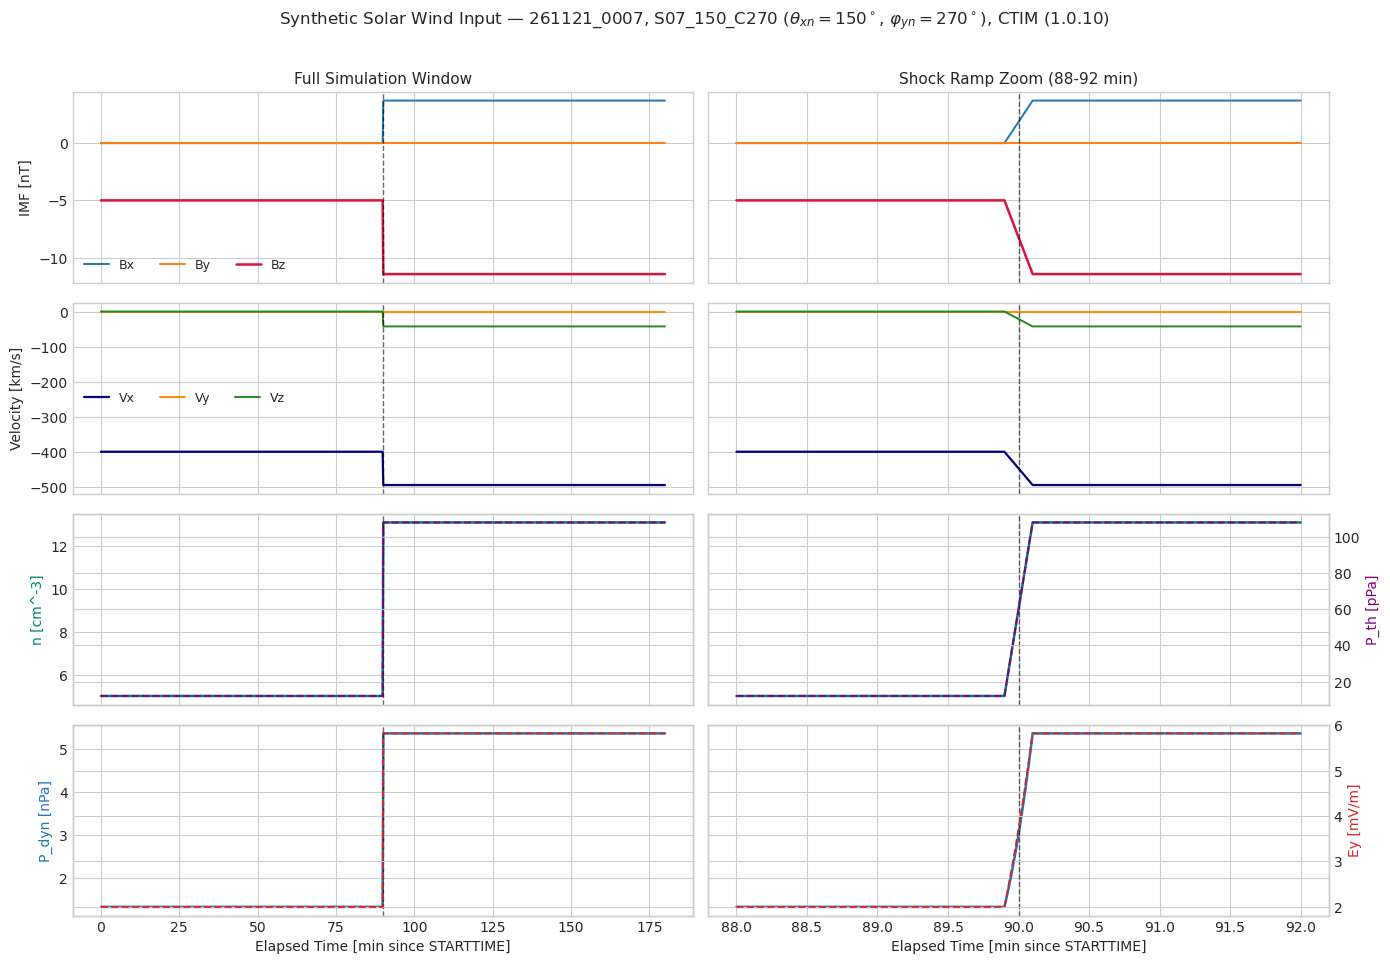

In [5]:
# Plot the full window and shock ramp solar wind input (GSE).
fig, axes = plt.subplots(4, 2, figsize=(14, 9.5), sharex="col", sharey="row")
zoom_lo, zoom_hi = SHOCK_TIME_MIN - 2.0, SHOCK_TIME_MIN + 2.0
sw_zoom = sw_df.loc[sw_df["t_min"].between(zoom_lo, zoom_hi)]

for col_idx, (df_plot, col_title) in enumerate(
    [
        (sw_sim, "Full Simulation Window"),
        (sw_zoom, f"Shock Ramp Zoom ({zoom_lo:.0f}-{zoom_hi:.0f} min)"),
    ]
):
    t = df_plot["t_min"].to_numpy()

    ax = axes[0, col_idx]
    ax.plot(t, df_plot["bx"], label="Bx", lw=1.4)
    ax.plot(t, df_plot["by"], label="By", lw=1.4)
    ax.plot(t, df_plot["bz"], label="Bz", lw=1.8, color="crimson")
    ax.axvline(SHOCK_TIME_MIN, color="k", ls="--", lw=1.0, alpha=0.6)
    ax.set_title(col_title, fontsize=11)
    if col_idx == 0:
        ax.set_ylabel("IMF [nT]")
        ax.legend(loc="lower left", ncol=3, fontsize=9)

    ax = axes[1, col_idx]
    ax.plot(t, df_plot["vx"], label="Vx", lw=1.6, color="navy")
    ax.plot(t, df_plot["vy"], label="Vy", lw=1.4, color="darkorange")
    ax.plot(t, df_plot["vz"], label="Vz", lw=1.4, color="forestgreen")
    ax.axvline(SHOCK_TIME_MIN, color="k", ls="--", lw=1.0, alpha=0.6)
    if col_idx == 0:
        ax.set_ylabel("Velocity [km/s]")
        ax.legend(loc="center left", ncol=3, fontsize=9)

    ax = axes[2, col_idx]
    ax.plot(t, df_plot["rr"], label="n [cm^-3]", lw=1.8, color="teal")
    ax.axvline(SHOCK_TIME_MIN, color="k", ls="--", lw=1.0, alpha=0.6)
    ax2 = ax.twinx()
    ax2.plot(t, df_plot["pp"], label="P [pPa]", lw=1.4, ls="--", color="purple")
    ax2.tick_params(labelright=(col_idx == 1))
    if col_idx == 0:
        ax.set_ylabel("n [cm^-3]", color="teal")
    else:
        ax2.set_ylabel("P_th [pPa]", color="purple")

    ax = axes[3, col_idx]
    ax.plot(t, df_plot["pdyn"], label="P_dyn [nPa]", lw=1.8, color="tab:blue")
    ax.axvline(SHOCK_TIME_MIN, color="k", ls="--", lw=1.0, alpha=0.6)
    ax2 = ax.twinx()
    ax2.plot(t, df_plot["ey"], label="Ey [mV/m]", lw=1.4, ls="--", color="tab:red")
    ax2.tick_params(labelright=(col_idx == 1))
    ax.set_xlabel("Elapsed Time [min since STARTTIME]")
    if col_idx == 0:
        ax.set_ylabel("P_dyn [nPa]", color="tab:blue")
    else:
        ax2.set_ylabel("Ey [mV/m]", color="tab:red")

fig.suptitle(f"Synthetic Solar Wind Input — {RUN_LABEL}", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 2. Ionosphere Output & Geomagnetic Indices

Computes northern & southern hemisphere indices (CPCP, total FAC, Joule heating, auroral indices AL/AU/AE, equatorial $\Delta B_H$, and global + AE-station R, broken down by the hemisphere, auroral or mid/low latitude, and dawn or dusk MLT)

In [6]:
def open_ggcm_series(
    data_dir: pathlib.Path,
    pattern: str,
    start_time: pd.Timestamp,
    time_slice_min: tuple[float, float] | None = None,
) -> xr.Dataset:
    """Open an OpenGGCM jrrle time series safely (tolerates a live in-progress last file)."""
    files = sorted(data_dir.glob(pattern))
    if not files:
        raise FileNotFoundError(f"No files matching {pattern} in {data_dir}")

    # Guard against a mid-write trailing file if the simulation is still running.
    while len(files) > 1:
        try:
            with xr.open_dataset(files[-1]) as _chk:
                _ = _chk.time.values
            break
        except Exception:
            warnings.warn(f"Skipping unreadable/in-progress file: {files[-1].name}")
            files.pop()

    ds = xr.open_mfdataset(
        files,
        data_vars="all",
        coords="minimal",
        compat="override",
    )
    if time_slice_min is not None:
        t0 = start_time + pd.Timedelta(minutes=time_slice_min[0])
        t1 = start_time + pd.Timedelta(minutes=time_slice_min[1])
        ds = ds.sel(time=slice(t0, t1))
    return ds


iof = open_ggcm_series(DATA_DIR, f"{RUN_NAME}.iof.*", START_TIME, TIME_SLICE_MIN)
n_iof = iof.sizes["time"]
iof_times = pd.to_datetime(iof.time.values)
iof_elapsed_min = (iof_times - START_TIME).total_seconds().to_numpy() / 60.0
iof_dt_shock_min = iof_elapsed_min - SHOCK_TIME_MIN
dt_iof_s = (
    float(np.median(np.diff(iof_times).astype("timedelta64[ms]").astype(float)) * 1e-3)
    if n_iof > 1
    else np.nan
)
HAS_POST_SHOCK = bool(iof_elapsed_min[-1] > SHOCK_TIME_MIN + 2.0)

print(f"Loaded iof: {n_iof} steps with dt = {dt_iof_s:.2f} s")
print(
    f"Time range: [{iof_times[0]}, {iof_times[-1]}] "
    f"({iof_elapsed_min[0]:.2f} to {iof_elapsed_min[-1]:.2f} min; "
    f"dt_shock = {iof_dt_shock_min[0]:+.2f} to {iof_dt_shock_min[-1]:+.2f} min)"
)
print(
    f"Grid: lats={iof.lats.size} ({float(iof.lats.min()):.1f},...,{float(iof.lats.max()):.1f} deg), "
    f"longs={iof.longs.size} ({float(iof.longs.min()):.1f},...,{float(iof.longs.max()):.1f} deg)"
)

Loaded iof: 1799 steps with dt = 6.00 s
Time range: [2000-09-21 00:00:06.018000, 2000-09-21 02:59:54.051000] (0.10 to 179.90 min; dt_shock = -89.90 to +89.90 min)
Grid: lats=361 (-90.0,...,90.0 deg), longs=121 (-180.0,...,180.0 deg)


In [7]:
# Load core 2D ionospheric fields into memory for fast index calculation.
core_vars = ["pot", "fac_tot", "xjh", "delbt", "delbp", "delbr", "sigp", "sigh"]
iof_core = iof[core_vars].load()

# Spherical area element dA [m^2] on the ionospheric grid
RE_M = 6371040.0
dtheta_rad = np.deg2rad(180.0 / (iof_core.lats.size - 1))
dphi_rad = np.deg2rad(360.0 / (iof_core.longs.size - 1))
darea = (RE_M * dtheta_rad * xr.ones_like(iof_core.longs)) * (
    RE_M * np.cos(np.deg2rad(iof_core.lats)) * dphi_rad
)

# Avoid double-counting the periodic seam longs=-180/+180.
lon_w = xr.ones_like(iof_core.longs)
if np.isclose(float(iof_core.longs[-1] - iof_core.longs[0]), 360.0):
    lon_w = lon_w.copy()
    lon_w[0] = 0.5
    lon_w[-1] = 0.5
darea_int = darea * lon_w

# 1. Cross-Polar-Cap Potential [kV] (NH & SH)
cpcp_n = iof_core.ggcm.cpcp("north") * 1e-3
cpcp_s = iof_core.ggcm.cpcp("south") * 1e-3
cpcp_n.attrs["units"] = "kV"
cpcp_s.attrs["units"] = "kV"

pot_nh = iof_core.pot.where(iof_core.lats > 0, drop=True) * 1e-3
pot_sh = iof_core.pot.where(iof_core.lats < 0, drop=True) * 1e-3
pot_max_n = pot_nh.max(dim=["lats", "longs"])
pot_min_n = pot_nh.min(dim=["lats", "longs"])
pot_max_s = pot_sh.max(dim=["lats", "longs"])
pot_min_s = pot_sh.min(dim=["lats", "longs"])

# 2. Field-Aligned Currents [MA]:
#    (a) Total FAC intensity = 0.5 * int(dA |J_{||}|) (NH & SH)
#    (b) Signed net FAC conservation check via iof.ggcm.fac()
fac_n = (0.5 * np.abs(iof_core.fac_tot) * darea_int).where(iof_core.lats > 0).sum(
    dim=["lats", "longs"]
) * 1e-6
fac_s = (0.5 * np.abs(iof_core.fac_tot) * darea_int).where(iof_core.lats < 0).sum(
    dim=["lats", "longs"]
) * 1e-6
fac_n = fac_n.rename("fac_north")
fac_s = fac_s.rename("fac_south")
fac_n.attrs.update(
    {"long_name": "Total FAC (North)", "name": "FAC North", "units": "MA"}
)
fac_s.attrs.update(
    {"long_name": "Total FAC (South)", "name": "FAC South", "units": "MA"}
)

fac_net_total = iof_core.ggcm.fac("total") * 1e-6
fac_net_total.attrs["units"] = "MA"

# 3. Integrated Joule Heating [GW] (NH & SH)
jh_n = iof_core.ggcm.jh("north") * 1e-9
jh_s = iof_core.ggcm.jh("south") * 1e-9
jh_n.attrs["units"] = "GW"
jh_s.attrs["units"] = "GW"

# 4. Surface Magnetic Indices [nT]: 12-station NH AL + unbiased global NH/SH AL, AU, AE + equatorial SI proxy
ggcm_al = iof_core.ggcm.al_index()
delbh_north_nT = (
    -iof_core["delbt"] * 1e9
)  # +northward horizontal surface magnetic perturbations (nT)

aur_nh_mask = (iof_core.lats >= 50.0) & (iof_core.lats <= 80.0)
aur_sh_mask = (iof_core.lats <= -50.0) & (iof_core.lats >= -80.0)
eq_mask = np.abs(iof_core.lats) <= 20.0

al_grid_n = (
    delbh_north_nT.where(aur_nh_mask).min(dim=["lats", "longs"]).rename("al_grid_north")
)
au_grid_n = (
    delbh_north_nT.where(aur_nh_mask).max(dim=["lats", "longs"]).rename("au_grid_north")
)
ae_grid_n = (au_grid_n - al_grid_n).rename("ae_grid_north")

al_grid_s = (
    delbh_north_nT.where(aur_sh_mask).min(dim=["lats", "longs"]).rename("al_grid_south")
)
au_grid_s = (
    delbh_north_nT.where(aur_sh_mask).max(dim=["lats", "longs"]).rename("au_grid_south")
)
ae_grid_s = (au_grid_s - al_grid_s).rename("ae_grid_south")

eq_dbh = delbh_north_nT.where(eq_mask).mean(dim=["lats", "longs"]).rename("eq_dbh")
eq_dbh.attrs.update(
    {"long_name": "Equatorial Mean B_H (|mlat|<=20)", "name": "Eq dB_H", "units": "nT"}
)

# 5. Magnitude of time derivatives of horizontal components of the surface magnetic perturbations, R = |dB_H/dt| [nT/s]: full grid + 12-station AE network
delbh_t_sim = iof_core.ggcm.delbhdelt()
delbh_t_sim_station = iof_core.ggcm.delbhdelt_station()

# Valid slice
R_valid = delbh_t_sim.isel(time=slice(1, None))
R_st_valid = delbh_t_sim_station.isel(time=slice(1, None))

# Global peak R by hemisphere, latitude band, and dawn (00-12 MLT: longs < 0) vs. dusk (12-24 MLT: longs > 0)
r_max_n = delbh_t_sim.where(iof_core.lats > 0).max(dim=["lats", "longs"])
r_max_s = delbh_t_sim.where(iof_core.lats < 0).max(dim=["lats", "longs"])
r_max_aur_n = delbh_t_sim.where(iof_core.lats >= 50.0).max(dim=["lats", "longs"])
r_max_aur_s = delbh_t_sim.where(iof_core.lats <= -50.0).max(dim=["lats", "longs"])
r_max_midlow_n = delbh_t_sim.where((iof_core.lats > 0.0) & (iof_core.lats < 50.0)).max(
    dim=["lats", "longs"]
)
r_max_midlow_s = delbh_t_sim.where((iof_core.lats < 0.0) & (iof_core.lats > -50.0)).max(
    dim=["lats", "longs"]
)

# Dawn (00-12 MLT -> longs < 0) vs. Dusk (12-24 MLT -> longs > 0) in polar/auroral zone
r_max_dawn_n = delbh_t_sim.where((iof_core.lats >= 50.0) & (iof_core.longs < 0.0)).max(
    dim=["lats", "longs"]
)
r_max_dusk_n = delbh_t_sim.where((iof_core.lats >= 50.0) & (iof_core.longs > 0.0)).max(
    dim=["lats", "longs"]
)
r_max_dawn_s = delbh_t_sim.where((iof_core.lats <= -50.0) & (iof_core.longs < 0.0)).max(
    dim=["lats", "longs"]
)
r_max_dusk_s = delbh_t_sim.where((iof_core.lats <= -50.0) & (iof_core.longs > 0.0)).max(
    dim=["lats", "longs"]
)

# Area-weighted mean auroral conductances [S] (50 <= |mlat| <= 80)
w_aur_n = darea_int.where(aur_nh_mask)
w_aur_s = darea_int.where(aur_sh_mask)
sigp_mean_n = (iof_core.sigp * w_aur_n).sum(dim=["lats", "longs"]) / w_aur_n.sum(
    dim=["lats", "longs"]
)
sigp_mean_s = (iof_core.sigp * w_aur_s).sum(dim=["lats", "longs"]) / w_aur_s.sum(
    dim=["lats", "longs"]
)
sigh_mean_n = (iof_core.sigh * w_aur_n).sum(dim=["lats", "longs"]) / w_aur_n.sum(
    dim=["lats", "longs"]
)
sigh_mean_s = (iof_core.sigh * w_aur_s).sum(dim=["lats", "longs"]) / w_aur_s.sum(
    dim=["lats", "longs"]
)

# Identify peak R events (station & global NH/SH, preferring post-shock when available).
post_mask_R = pd.to_datetime(R_valid.time.values) >= SHOCK_TIME_TS
R_search = (
    R_valid.isel(time=post_mask_R)
    if (HAS_POST_SHOCK and post_mask_R.any())
    else R_valid
)
R_st_search = (
    R_st_valid.isel(time=post_mask_R)
    if (HAS_POST_SHOCK and post_mask_R.any())
    else R_st_valid
)


def find_peak_3d(da_3d: xr.DataArray) -> dict:
    idx = da_3d.argmax(dim=["time", "lats", "longs"])
    t_pk = pd.Timestamp(da_3d.time.values[int(idx["time"])])
    lat_pk = float(da_3d.lats.values[int(idx["lats"])])
    lon_pk = float(da_3d.longs.values[int(idx["longs"])])
    mlt_pk = ((lon_pk + 180.0) % 360.0) / 15.0
    val_pk = float(
        da_3d.isel(
            time=int(idx["time"]), lats=int(idx["lats"]), longs=int(idx["longs"])
        )
    )
    return {
        "val": val_pk,
        "time": t_pk,
        "t_min": (t_pk - START_TIME).total_seconds() / 60.0,
        "dt_shock_min": (t_pk - SHOCK_TIME_TS).total_seconds() / 60.0,
        "mlat": lat_pk,
        "mlon": lon_pk,
        "mlt": mlt_pk,
    }


peak_R_nh = find_peak_3d(R_search.where(iof_core.lats > 0, drop=True))
peak_R_sh = find_peak_3d(R_search.where(iof_core.lats < 0, drop=True))

st_idx = R_st_search.argmax(dim=["time", "station"])
station_max_sim_name = str(R_st_search.station.values[int(st_idx["station"])])
station_max_sim_time = R_st_search.time.values[int(st_idx["time"])]
station_max_sim_val = float(
    R_st_search.isel(time=int(st_idx["time"]), station=int(st_idx["station"]))
)
station_max_dt_shock = (
    pd.Timestamp(station_max_sim_time) - SHOCK_TIME_TS
).total_seconds() / 60.0

print(
    f"Peak Global R (NH): {peak_R_nh['val']:.2f} nT/s at t={peak_R_nh['t_min']:.2f} min (dt_shock={peak_R_nh['dt_shock_min']:+.2f} min), MLAT={peak_R_nh['mlat']:+.1f} deg, MLON={peak_R_nh['mlon']:.1f} deg"
)
print(
    f"Peak Global R (SH): {peak_R_sh['val']:.2f} nT/s at t={peak_R_sh['t_min']:.2f} min (dt_shock={peak_R_sh['dt_shock_min']:+.2f} min), MLAT={peak_R_sh['mlat']:+.1f} deg, MLON={peak_R_sh['mlon']:.1f} deg"
)
print(
    f"Peak AE-Station R: {station_max_sim_val:.2f} nT/s at t={station_max_sim_time} (dt_shock={station_max_dt_shock:+.2f} min), at {station_max_sim_name}"
)

# Register key variables into pyspedas for tplot.
t_iof_arr = iof_core.time.values
store_to_pyspedas(ggcm_al["ggcm.al"])
store_to_pyspedas(cpcp_n)
store_to_pyspedas(cpcp_s)
store_to_pyspedas(jh_n)
store_to_pyspedas(jh_s)
store_to_pyspedas(fac_n)
store_to_pyspedas(fac_s)
store_to_pyspedas(fac_net_total)
store_to_pyspedas(eq_dbh)

for name, da in [
    ("al_grid_north", al_grid_n),
    ("al_grid_south", al_grid_s),
    ("r_max_north", r_max_n),
    ("r_max_south", r_max_s),
    ("r_max_dawn_north", r_max_dawn_n),
    ("r_max_dusk_north", r_max_dusk_n),
]:
    store_data(name, data={"x": t_iof_arr, "y": da.values})

stations = delbh_t_sim_station.station
station_var_names = []
for stn in stations.values:
    vname = f"delbh_t_sim_{stn}"
    store_data(
        vname,
        data={
            "x": delbh_t_sim_station.time.values,
            "y": delbh_t_sim_station.sel(station=stn).values,
        },
    )
    station_var_names.append(vname)
store_data("delbh_t_sim_all", data=station_var_names)

# Grouped multi-trace tplot variables (NH vs. SH)
_ = store_data("al_nh_sh", data=["al_grid_north", "al_grid_south", "ggcm.al"])
_ = store_data(
    "r_max_nh_sh",
    data=["r_max_north", "r_max_south", f"delbh_t_sim_{station_max_sim_name}"],
)
_ = store_data("cpcp_nh_sh", data=["cpcp_north", "cpcp_south"])
_ = store_data("jh_nh_sh", data=["jh_north", "jh_south"])
_ = store_data("fac_nh_sh", data=["fac_north", "fac_south"])

Peak Global R (NH): 8.39 nT/s at t=177.00 min (dt_shock=+87.00 min), MLAT=+65.5 deg, MLON=66.0 deg
Peak Global R (SH): 14.07 nT/s at t=173.10 min (dt_shock=+83.10 min), MLAT=-69.0 deg, MLON=-165.0 deg
Peak AE-Station R: 4.62 nT/s at t=2000-09-21T02:59:00.068000000 (dt_shock=+89.00 min), at ABK


In [8]:
# Build a quantitative shock-response summary table (& an optional CSV export).
idx_df = pd.DataFrame(
    {
        "t_min": iof_elapsed_min,
        "dt_shock_min": iof_dt_shock_min,
        "CPCP_N_kV": cpcp_n.values,
        "CPCP_S_kV": cpcp_s.values,
        "FAC_N_MA": fac_n.values,
        "FAC_S_MA": fac_s.values,
        "FAC_Net_Total_MA": fac_net_total.values,
        "JH_N_GW": jh_n.values,
        "JH_S_GW": jh_s.values,
        "AL_grid_N_nT": al_grid_n.values,
        "AL_grid_S_nT": al_grid_s.values,
        "AL_12stn_nT": ggcm_al["ggcm.al"].values,
        "AE_grid_N_nT": ae_grid_n.values,
        "AE_grid_S_nT": ae_grid_s.values,
        "Eq_dBH_nT": eq_dbh.values,
        "R_max_N_nTs": r_max_n.values,
        "R_max_S_nTs": r_max_s.values,
        "R_aur_N_nTs": r_max_aur_n.values,
        "R_aur_S_nTs": r_max_aur_s.values,
        "R_midlow_N_nTs": r_max_midlow_n.values,
        "R_midlow_S_nTs": r_max_midlow_s.values,
        "R_dawn_N_nTs": r_max_dawn_n.values,
        "R_dusk_N_nTs": r_max_dusk_n.values,
        "R_dawn_S_nTs": r_max_dawn_s.values,
        "R_dusk_S_nTs": r_max_dusk_s.values,
        "R_12stn_max_nTs": delbh_t_sim_station.max(dim="station").values,
        "SigP_aur_N_S": sigp_mean_n.values,
        "SigP_aur_S_S": sigp_mean_s.values,
        "SigH_aur_N_S": sigh_mean_n.values,
        "SigH_aur_S_S": sigh_mean_s.values,
    },
    index=iof_times,
)

w_pre = idx_df["t_min"].between(SHOCK_TIME_MIN - 16.0, SHOCK_TIME_MIN - 2.0)
w_si = idx_df["t_min"].between(SHOCK_TIME_MIN, SHOCK_TIME_MIN + 16.0)
w_post = idx_df["t_min"] >= SHOCK_TIME_MIN

metric_specs = [
    ("CPCP_N_kV", "max"),
    ("CPCP_S_kV", "max"),
    ("FAC_N_MA", "max"),
    ("FAC_S_MA", "max"),
    ("JH_N_GW", "max"),
    ("JH_S_GW", "max"),
    ("AL_grid_N_nT", "min"),
    ("AL_grid_S_nT", "min"),
    ("AL_12stn_nT", "min"),
    ("Eq_dBH_nT", "max"),
    ("R_max_N_nTs", "max"),
    ("R_max_S_nTs", "max"),
    ("R_midlow_N_nTs", "max"),
    ("R_midlow_S_nTs", "max"),
    ("R_dawn_N_nTs", "max"),
    ("R_dusk_N_nTs", "max"),
    ("R_12stn_max_nTs", "max"),
    ("SigP_aur_N_S", "max"),
    ("SigH_aur_N_S", "max"),
]

rows = []
for col, mode in metric_specs:
    pre_mean = float(idx_df.loc[w_pre, col].mean()) if w_pre.any() else np.nan
    si_sub = idx_df.loc[w_si, col].dropna()
    post_sub = idx_df.loc[w_post, col].dropna()

    def _ext(s: pd.Series):
        if s.empty:
            return np.nan, np.nan
        t_ext = s.idxmin() if mode == "min" else s.idxmax()
        return float(s.loc[t_ext]), float(idx_df.loc[t_ext, "dt_shock_min"])

    si_val, si_dt = _ext(si_sub)
    post_val, post_dt = _ext(post_sub)
    rows.append(
        {
            "Metric": col,
            "Pre-Shock Mean (-16,...,-2 min)": pre_mean,
            "SI Peak (0,...,+16 min)": si_val,
            "SI dt_shock [min]": si_dt,
            "Post-Shock Peak (>=0 min)": post_val,
            "Post dt_shock [min]": post_dt,
        }
    )

metrics_df = pd.DataFrame(rows).set_index("Metric")
display(metrics_df.round(3))

# Asymmetry summary (NH/SH & Dawn/Dusk)
if HAS_POST_SHOCK:
    nh_sh_R = metrics_df.loc["R_max_N_nTs", "Post-Shock Peak (>=0 min)"] / max(
        metrics_df.loc["R_max_S_nTs", "Post-Shock Peak (>=0 min)"], 1e-12
    )
    nh_sh_AL = metrics_df.loc["AL_grid_N_nT", "Post-Shock Peak (>=0 min)"] / min(
        metrics_df.loc["AL_grid_S_nT", "Post-Shock Peak (>=0 min)"], -1e-12
    )
    nh_sh_CPCP = metrics_df.loc["CPCP_N_kV", "Post-Shock Peak (>=0 min)"] / max(
        metrics_df.loc["CPCP_S_kV", "Post-Shock Peak (>=0 min)"], 1e-12
    )
    dawn_dusk_R_n = metrics_df.loc["R_dawn_N_nTs", "Post-Shock Peak (>=0 min)"] / max(
        metrics_df.loc["R_dusk_N_nTs", "Post-Shock Peak (>=0 min)"], 1e-12
    )
    print(
        f"Post-shock asymmetry ratios: "
        f"NH/SH R_max = {nh_sh_R:.3f}, NH/SH AL = {nh_sh_AL:.3f}, "
        f"NH/SH CPCP = {nh_sh_CPCP:.3f}, Dawn/Dusk R_max (NH) = {dawn_dusk_R_n:.3f}"
    )

if EXPORT_METRICS_CSV:
    try:
        PLOTS_DIR.mkdir(parents=True, exist_ok=True)
        csv_path = PLOTS_DIR / f"metrics_{RUN_NAME}.csv"
        out_df = metrics_df.copy()
        out_df.insert(0, "conductance", CONDUCTANCE_MODEL)
        out_df.insert(0, "phi_yn_deg", PHI_YN)
        out_df.insert(0, "theta_xn_deg", THETA_XN)
        out_df.insert(0, "shock_id", SHOCK_ID)
        out_df.insert(0, "run_name", RUN_NAME)
        out_df.to_csv(csv_path)
        print(f"Saved metrics CSV: {csv_path}")
    except OSError as exc:
        print(f"Skipping metrics CSV export ({exc})")

,"Pre-Shock Mean (-16,...,-2 min)","SI Peak (0,...,+16 min)",SI dt_shock [min],Post-Shock Peak (>=0 min),Post dt_shock [min]
Metric,,,,,
CPCP_N_kV,236.882,421.756,15.301,549.503,72.001
CPCP_S_kV,221.694,378.321,15.000,408.248,65.000
FAC_N_MA,6.402,8.241,9.200,27.208,89.901
FAC_S_MA,6.763,8.698,15.301,23.484,89.901
JH_N_GW,316.768,1003.072,15.000,2175.602,75.601
JH_S_GW,370.106,1210.975,15.900,1932.903,79.001
AL_grid_N_nT,-92.361,-231.882,15.900,-521.742,79.101
AL_grid_S_nT,-290.870,-558.943,15.900,-1140.767,76.401
AL_12stn_nT,-34.087,-74.962,15.900,-416.261,78.500


Post-shock asymmetry ratios: NH/SH R_max = 0.596, NH/SH AL = 0.457, NH/SH CPCP = 1.346, Dawn/Dusk R_max (NH) = 0.675
Saved metrics CSV: /mnt/home/germaschewski/cu1010/runs/261121_0007/plots/metrics_261121_0007.csv


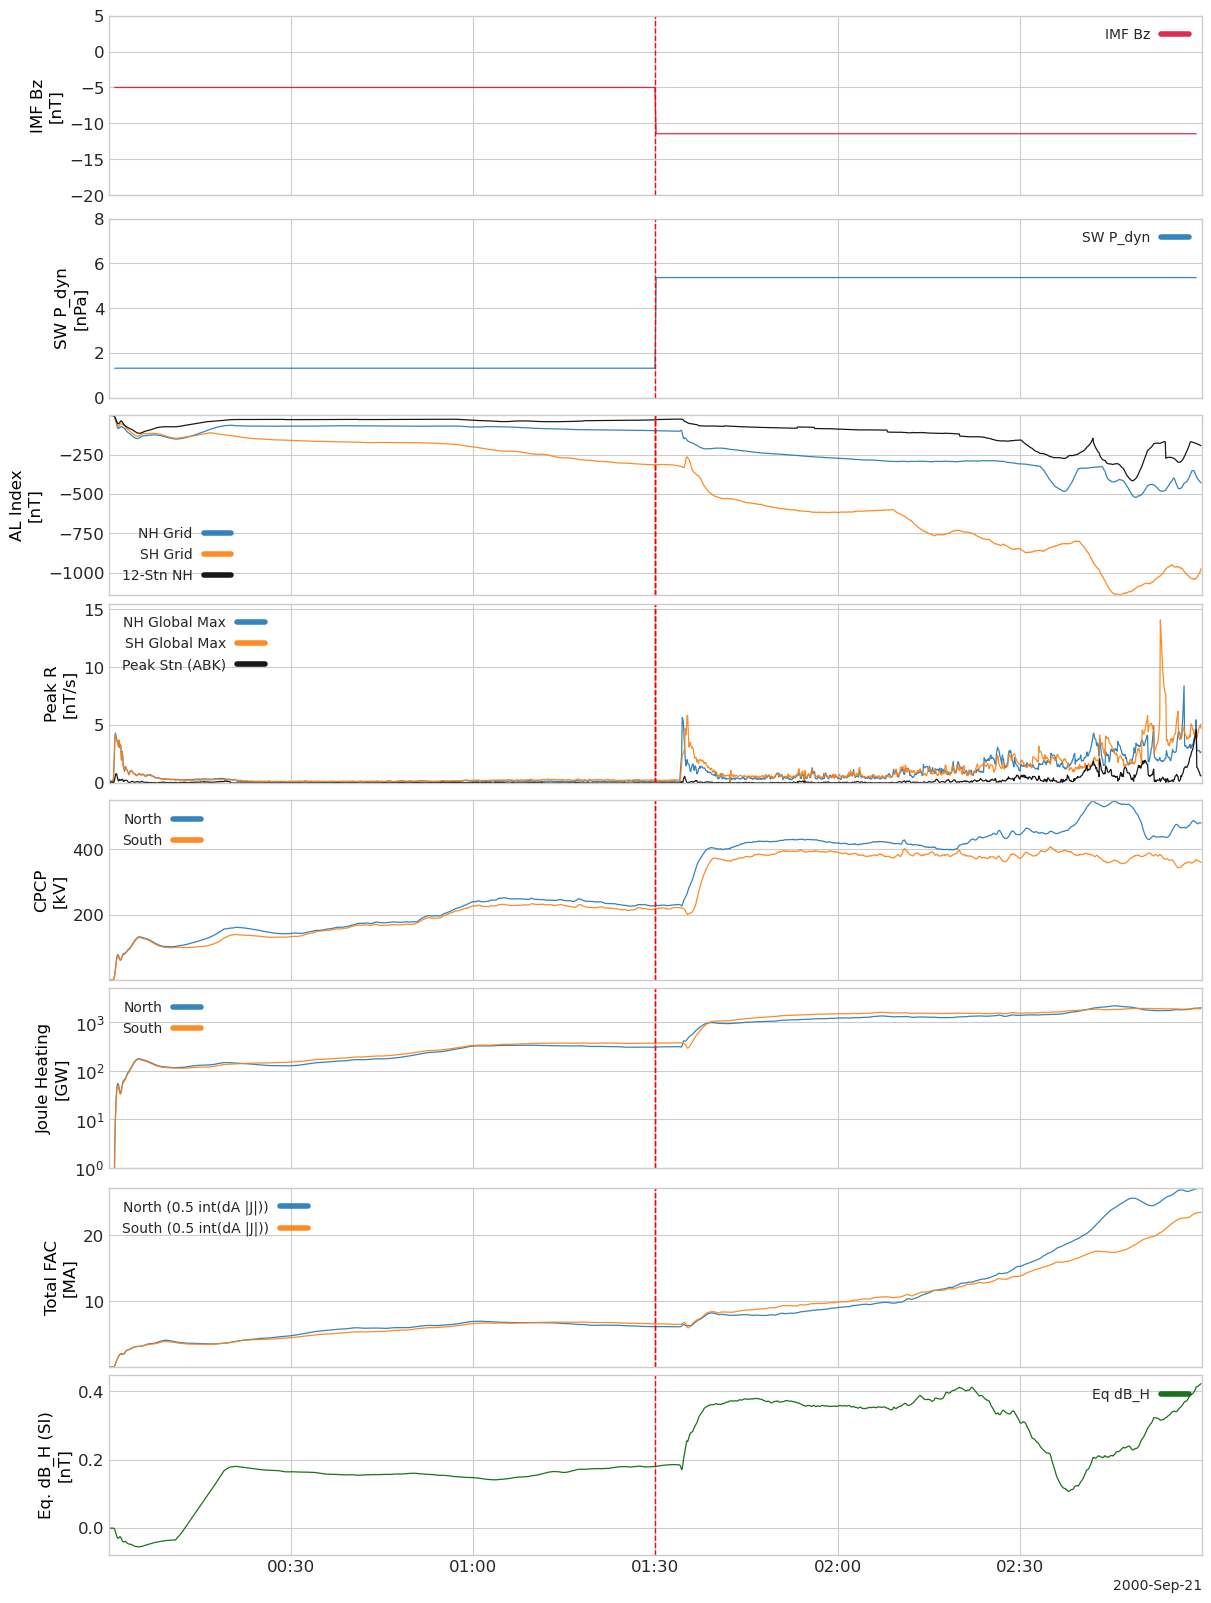

Shock-window zoom: [2000-09-21/01:20:00, 2000-09-21/02:20:00]


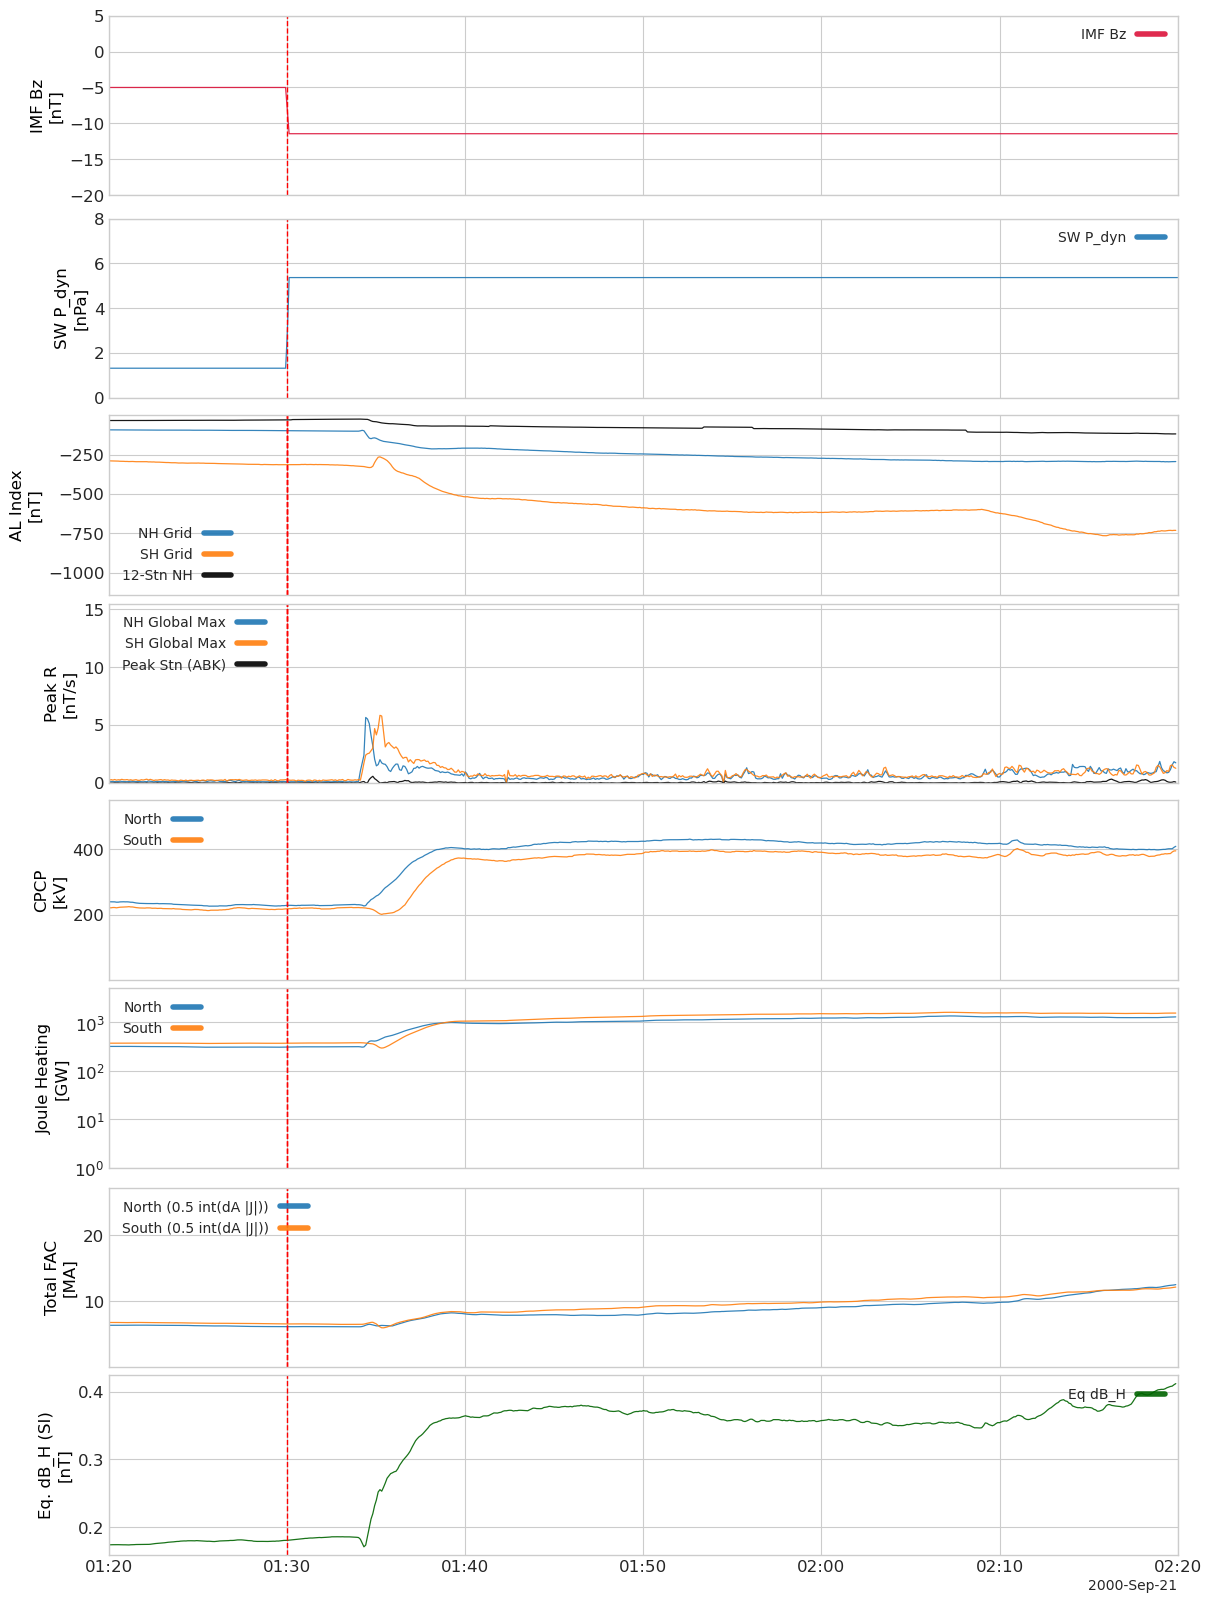

In [9]:
# Configure and plot a multi-panel geomagnetic overview with pyspedas.tplot.
options("sw_bz", "ytitle", "IMF Bz")
options("sw_bz", "yrange", [-20, 5])
options("sw_bz", "color", "crimson")

options("sw_pdyn", "ytitle", "SW P_dyn")
options("sw_pdyn", "yrange", [0, 8])
options("sw_pdyn", "color", "tab:blue")

options("al_nh_sh", "ytitle", "AL Index")
options("al_nh_sh", "ysubtitle", "[nT]")
options("al_nh_sh", "color", ["tab:blue", "tab:orange", "black"])
options("al_nh_sh", "legend_names", ["NH Grid", "SH Grid", "12-Stn NH"])
options("al_nh_sh", "legend_location", "lower left")

r_global_hi = max(6.0, float(np.nanmax([r_max_n.max(), r_max_s.max()])) * 1.1)
options("r_max_nh_sh", "ytitle", "Peak R")
options("r_max_nh_sh", "ysubtitle", "[nT/s]")
options("r_max_nh_sh", "yrange", [0, r_global_hi])
options("r_max_nh_sh", "color", ["tab:blue", "tab:orange", "black"])
options(
    "r_max_nh_sh",
    "legend_names",
    ["NH Global Max", "SH Global Max", f"Peak Stn ({station_max_sim_name})"],
)
options("r_max_nh_sh", "legend_location", "upper left")

options("cpcp_nh_sh", "ytitle", "CPCP")
options("cpcp_nh_sh", "ysubtitle", "[kV]")
options("cpcp_nh_sh", "color", ["tab:blue", "tab:orange"])
options("cpcp_nh_sh", "legend_names", ["North", "South"])
options("cpcp_nh_sh", "legend_location", "upper left")

options("jh_nh_sh", "ytitle", "Joule Heating")
options("jh_nh_sh", "ysubtitle", "[GW]")
options("jh_nh_sh", "ylog", True)
options(
    "jh_nh_sh",
    "yrange",
    [1, max(5000, float(np.nanmax([jh_n.max(), jh_s.max()])) * 1.5)],
)
options("jh_nh_sh", "color", ["tab:blue", "tab:orange"])
options("jh_nh_sh", "legend_names", ["North", "South"])
options("jh_nh_sh", "legend_location", "upper left")

options("fac_nh_sh", "ytitle", "Total FAC")
options("fac_nh_sh", "ysubtitle", "[MA]")
options("fac_nh_sh", "color", ["tab:blue", "tab:orange"])
options(
    "fac_nh_sh", "legend_names", ["North (0.5 int(dA |J|))", "South (0.5 int(dA |J|))"]
)
options("fac_nh_sh", "legend_location", "upper left")

options("eq_dbh", "ytitle", "Eq. dB_H (SI)")
options("eq_dbh", "ysubtitle", "[nT]")
options("eq_dbh", "color", "darkgreen")

overview_vars = [
    "sw_bz",
    "sw_pdyn",
    "al_nh_sh",
    "r_max_nh_sh",
    "cpcp_nh_sh",
    "jh_nh_sh",
    "fac_nh_sh",
    "eq_dbh",
]
options(overview_vars, "alpha", 0.9)
options(overview_vars, "line_width", 0.9)

# Add vertical shock arrival marker across all tplot variables (including grouped sub-traces).
timebar(SHOCK_TIME_TS.strftime("%Y-%m-%d/%H:%M:%S"), color="red", dash=True)

trange_full = [
    iof_times[0].strftime("%Y-%m-%d/%H:%M:%S"),
    iof_times[-1].strftime("%Y-%m-%d/%H:%M:%S"),
]
tplot(overview_vars, trange=trange_full, ysize=2.0 * len(overview_vars))

# Zoomed shock-response window (if available)
if HAS_POST_SHOCK:
    t_z0 = max(iof_times[0], START_TIME + pd.Timedelta(minutes=SHOCK_WINDOW_MIN[0]))
    t_z1 = min(iof_times[-1], START_TIME + pd.Timedelta(minutes=SHOCK_WINDOW_MIN[1]))
    trange_zoom = [
        t_z0.strftime("%Y-%m-%d/%H:%M:%S"),
        t_z1.strftime("%Y-%m-%d/%H:%M:%S"),
    ]
    print(f"Shock-window zoom: [{trange_zoom[0]}, {trange_zoom[1]}]")
    tplot(overview_vars, trange=trange_zoom, ysize=2.0 * len(overview_vars))

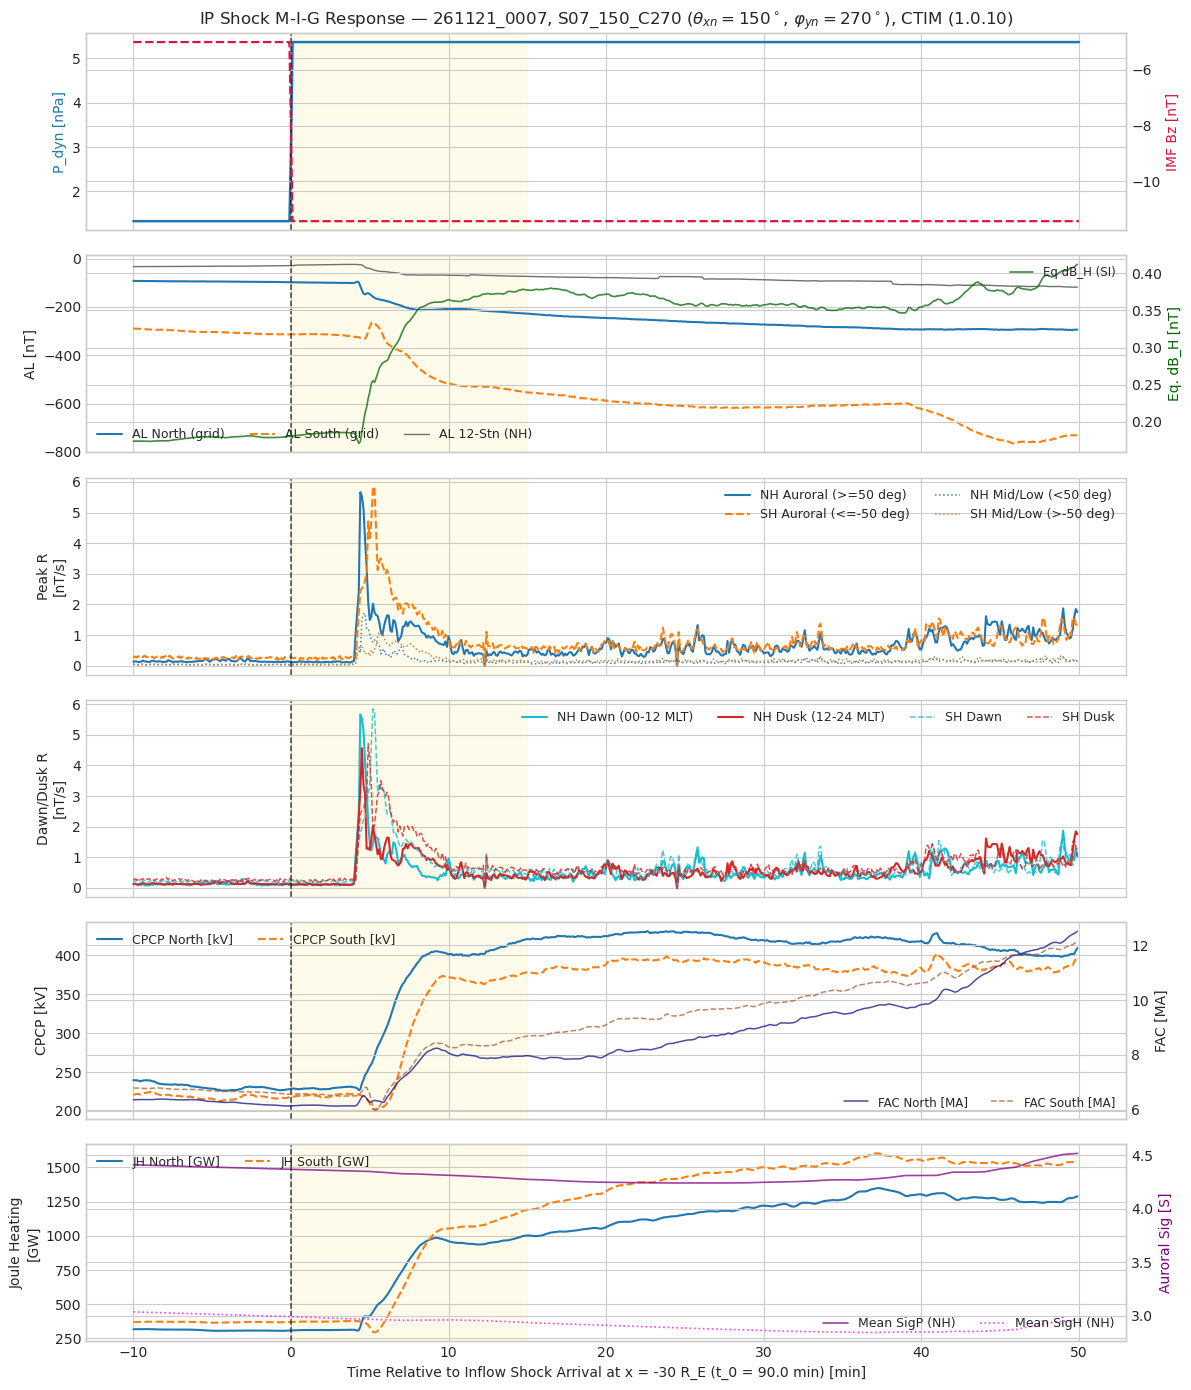

In [10]:
# 6-panel shock-response summary on shared (t - t_shock) [min] axis
w_lo = SHOCK_WINDOW_MIN[0] - SHOCK_TIME_MIN
w_hi = min(SHOCK_WINDOW_MIN[1], iof_elapsed_min[-1]) - SHOCK_TIME_MIN
if not HAS_POST_SHOCK:
    w_lo, w_hi = float(iof_dt_shock_min[0]), float(iof_dt_shock_min[-1])

m_idx = idx_df["dt_shock_min"].between(w_lo, w_hi)
sub = idx_df.loc[m_idx]
sw_sub = sw_df.loc[(sw_df["t_min"] - SHOCK_TIME_MIN).between(w_lo, w_hi)]

fig, axes = plt.subplots(6, 1, figsize=(12, 14), sharex=True)
dt_x = sub["dt_shock_min"].to_numpy()

# 1. Solar wind driver
ax = axes[0]
ax.plot(
    sw_sub["t_min"] - SHOCK_TIME_MIN,
    sw_sub["pdyn"],
    color="tab:blue",
    lw=1.8,
    label="P_dyn [nPa]",
)
ax.set_ylabel("P_dyn [nPa]", color="tab:blue")
ax2 = ax.twinx()
ax2.plot(
    sw_sub["t_min"] - SHOCK_TIME_MIN,
    sw_sub["bz"],
    color="crimson",
    lw=1.6,
    ls="--",
    label="IMF Bz [nT]",
)
ax2.set_ylabel("IMF Bz [nT]", color="crimson")
ax.set_title(f"IP Shock M-I-G Response — {RUN_LABEL}", fontsize=12)

# 2. AL (NH vs. SH) & Equatorial SI step
ax = axes[1]
ax.plot(dt_x, sub["AL_grid_N_nT"], color="tab:blue", lw=1.5, label="AL North (grid)")
ax.plot(
    dt_x,
    sub["AL_grid_S_nT"],
    color="tab:orange",
    lw=1.5,
    ls="--",
    label="AL South (grid)",
)
ax.plot(
    dt_x, sub["AL_12stn_nT"], color="0.3", lw=1.0, alpha=0.8, label="AL 12-Stn (NH)"
)
ax.set_ylabel("AL [nT]")
ax.legend(loc="lower left", ncol=3, fontsize=9)
ax2 = ax.twinx()
ax2.plot(
    dt_x, sub["Eq_dBH_nT"], color="darkgreen", lw=1.2, alpha=0.75, label="Eq dB_H (SI)"
)
ax2.set_ylabel("Eq. dB_H [nT]", color="darkgreen")
ax2.legend(loc="upper right", fontsize=8.5)

# 3. Global Peak R (NH vs. SH, Auroral vs. Mid/Low-Lat)
ax = axes[2]
ax.plot(
    dt_x, sub["R_aur_N_nTs"], color="tab:blue", lw=1.5, label="NH Auroral (>=50 deg)"
)
ax.plot(
    dt_x,
    sub["R_aur_S_nTs"],
    color="tab:orange",
    lw=1.5,
    ls="--",
    label="SH Auroral (<=-50 deg)",
)
ax.plot(
    dt_x,
    sub["R_midlow_N_nTs"],
    color="steelblue",
    lw=1.1,
    ls=":",
    label="NH Mid/Low (<50 deg)",
)
ax.plot(
    dt_x,
    sub["R_midlow_S_nTs"],
    color="peru",
    lw=1.1,
    ls=":",
    label="SH Mid/Low (>-50 deg)",
)
ax.set_ylabel("Peak R\n[nT/s]")
ax.legend(loc="upper right", ncol=2, fontsize=9)

# 4. Dawn vs. Dusk Peak R (NH & SH)
ax = axes[3]
ax.plot(
    dt_x, sub["R_dawn_N_nTs"], color="tab:cyan", lw=1.5, label="NH Dawn (00-12 MLT)"
)
ax.plot(dt_x, sub["R_dusk_N_nTs"], color="tab:red", lw=1.5, label="NH Dusk (12-24 MLT)")
ax.plot(
    dt_x,
    sub["R_dawn_S_nTs"],
    color="tab:cyan",
    lw=1.1,
    ls="--",
    alpha=0.8,
    label="SH Dawn",
)
ax.plot(
    dt_x,
    sub["R_dusk_S_nTs"],
    color="tab:red",
    lw=1.1,
    ls="--",
    alpha=0.8,
    label="SH Dusk",
)
ax.set_ylabel("Dawn/Dusk R\n[nT/s]")
ax.legend(loc="upper right", ncol=4, fontsize=9)

# 5. CPCP & Total FAC (NH vs. SH)
ax = axes[4]
ax.plot(dt_x, sub["CPCP_N_kV"], color="tab:blue", lw=1.5, label="CPCP North [kV]")
ax.plot(
    dt_x, sub["CPCP_S_kV"], color="tab:orange", lw=1.5, ls="--", label="CPCP South [kV]"
)
ax.set_ylabel("CPCP [kV]")
ax.legend(loc="upper left", ncol=2, fontsize=9)
ax2 = ax.twinx()
ax2.plot(dt_x, sub["FAC_N_MA"], color="navy", lw=1.1, alpha=0.7, label="FAC North [MA]")
ax2.plot(
    dt_x,
    sub["FAC_S_MA"],
    color="sienna",
    lw=1.1,
    ls="--",
    alpha=0.7,
    label="FAC South [MA]",
)
ax2.set_ylabel("FAC [MA]")
ax2.legend(loc="lower right", ncol=2, fontsize=8.5)

# 6. Joule Heating & Mean Auroral Conductances
ax = axes[5]
ax.plot(dt_x, sub["JH_N_GW"], color="tab:blue", lw=1.5, label="JH North [GW]")
ax.plot(
    dt_x, sub["JH_S_GW"], color="tab:orange", lw=1.5, ls="--", label="JH South [GW]"
)
ax.set_ylabel("Joule Heating\n[GW]")
ax.set_xlabel(
    f"Time Relative to Inflow Shock Arrival at x = -30 R_E (t_0 = {SHOCK_TIME_MIN:.1f} min) [min]"
)
ax.legend(loc="upper left", ncol=2, fontsize=9)
ax2 = ax.twinx()
ax2.plot(
    dt_x,
    sub["SigP_aur_N_S"],
    color="purple",
    lw=1.2,
    alpha=0.75,
    label="Mean SigP (NH)",
)
ax2.plot(
    dt_x,
    sub["SigH_aur_N_S"],
    color="magenta",
    lw=1.2,
    ls=":",
    alpha=0.75,
    label="Mean SigH (NH)",
)
ax2.set_ylabel("Auroral Sig [S]", color="purple")
ax2.legend(loc="lower right", ncol=2, fontsize=9)

for ax in axes:
    ax.axvline(0.0, color="k", ls="--", lw=1.1, alpha=0.7)
    if HAS_POST_SHOCK:
        ax.axvspan(0.0, 15.0, color="gold", alpha=0.08)

plt.tight_layout()
plt.show()

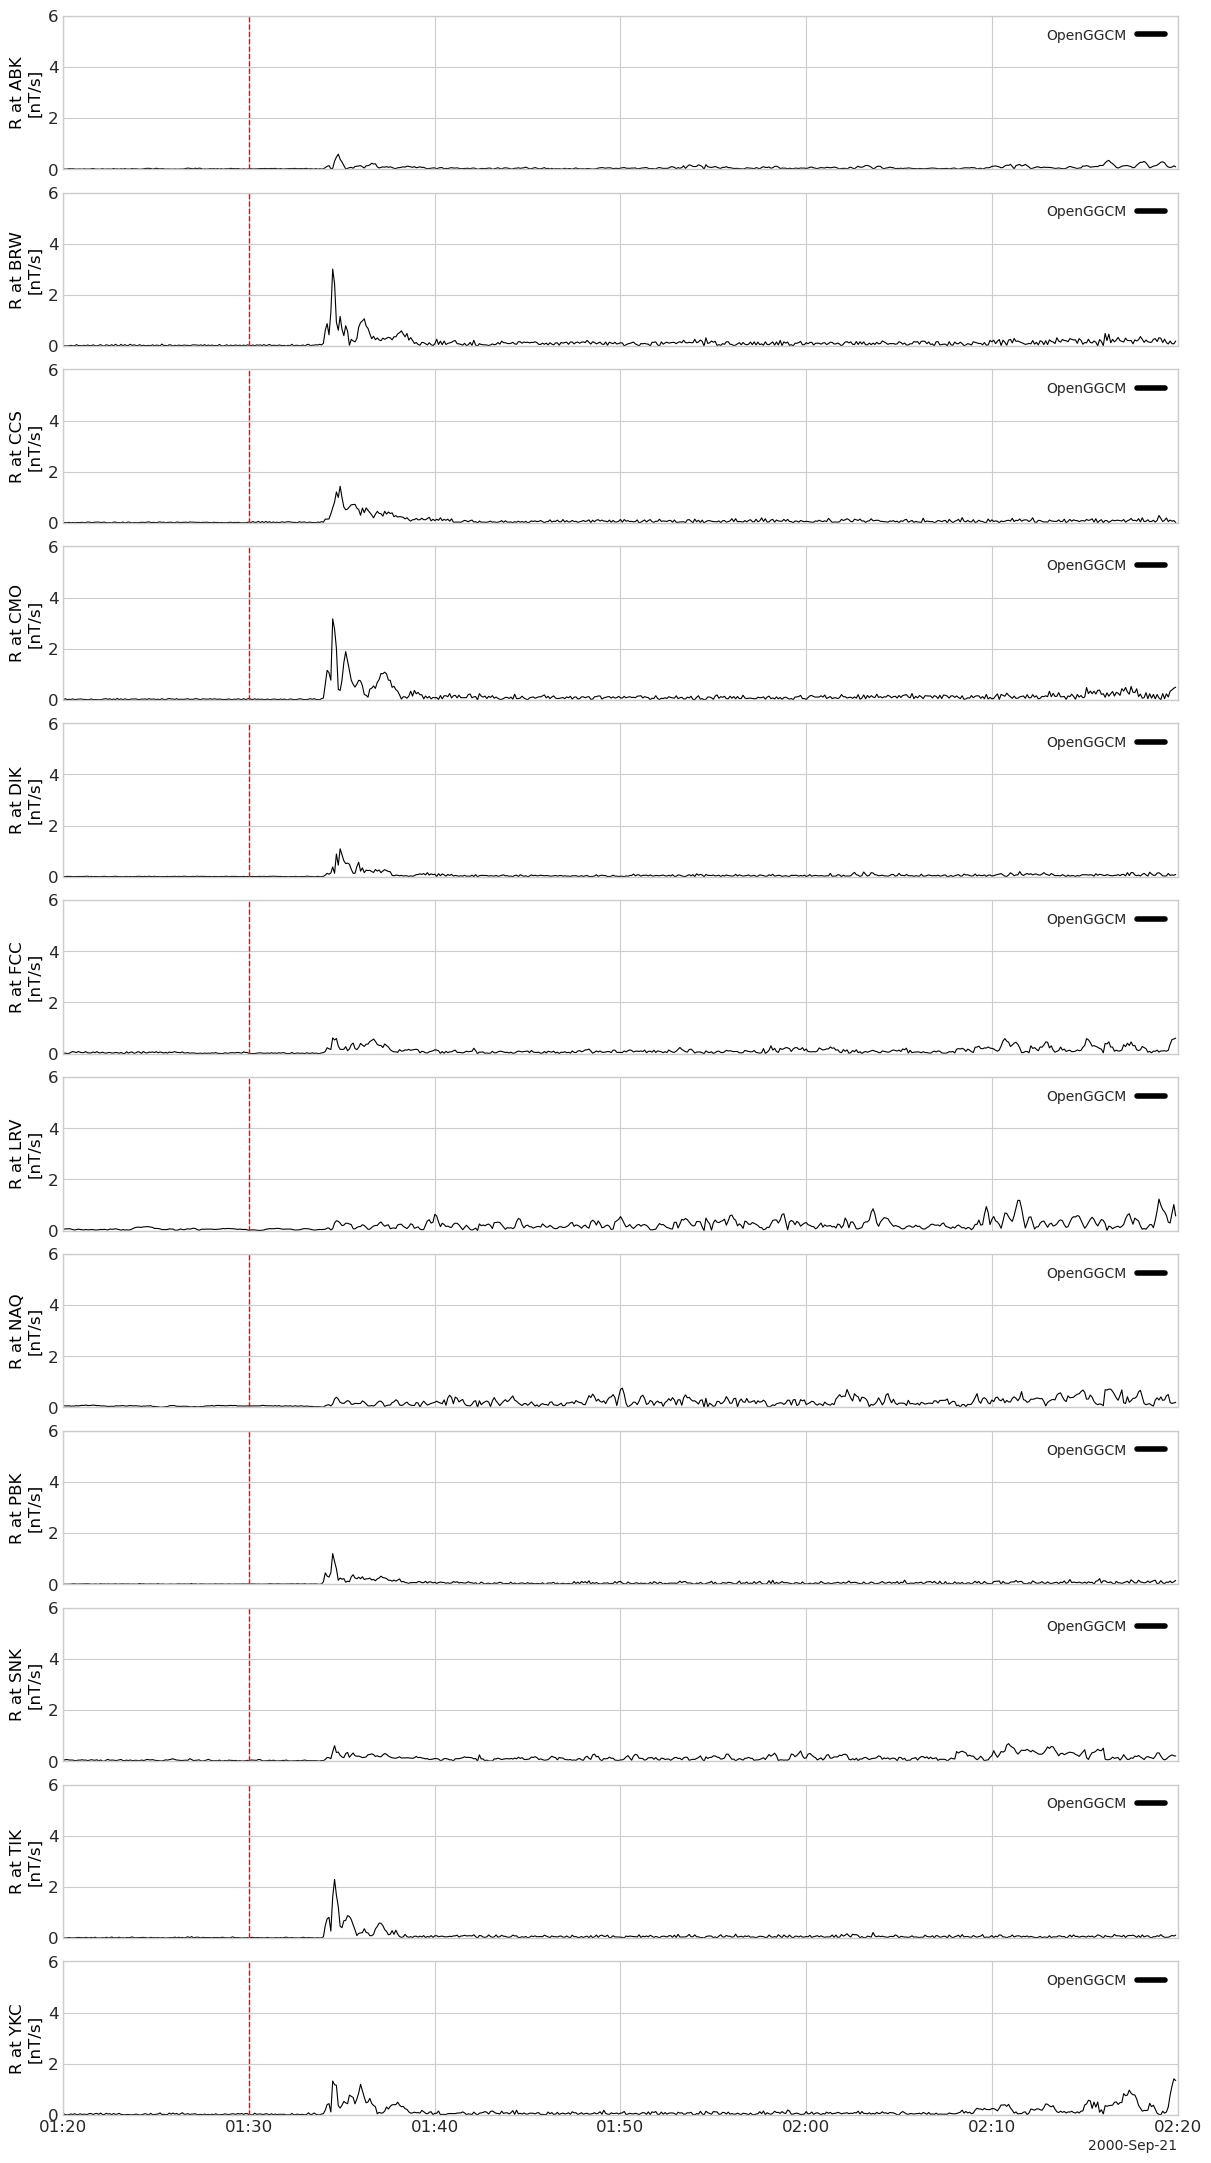

In [11]:
# Plot R at the 12 AE magnetometer stations.
r_stn_yrange = [0.0, max(6.0, float(np.ceil(station_max_sim_val * 1.15)))]
station_plot_vars = []
for stn in stations.values:
    vname = f"delbh_t_sim_{stn}"
    station_plot_vars.append(vname)
    options(vname, "ytitle", f"R at {stn}")
    options(vname, "ysubtitle", "[nT/s]")

options(station_plot_vars, "yrange", r_stn_yrange)
options(station_plot_vars, "alpha", 1.0)
options(station_plot_vars, "line_width", 0.8)
options(station_plot_vars, "legend_names", "OpenGGCM")
options(station_plot_vars, "legend_location", "upper right")

trange_stn = trange_zoom if HAS_POST_SHOCK else trange_full
tplot(station_plot_vars, trange=trange_stn, ysize=1.8 * len(station_plot_vars))

## 3. The Magnetosphere Structure (px_0: yz-plane, py_0: xz-plane, pz_0: xy-plane)

Inspects IP shock propagation, magnetopause compression, and 3D clock-angle asymmetry across all three principal planes at OpenGGCM's MHD cadence (60 s, decoupled from iof's 6 s cadence)

In [12]:
# Load 2D magnetosphere planes.
py_0 = open_ggcm_series(DATA_DIR, f"{RUN_NAME}.py_0.*", START_TIME, TIME_SLICE_MIN)
pz_0 = open_ggcm_series(DATA_DIR, f"{RUN_NAME}.pz_0.*", START_TIME, TIME_SLICE_MIN)
px_0 = open_ggcm_series(DATA_DIR, f"{RUN_NAME}.px_0.*", START_TIME, TIME_SLICE_MIN)

n_mhd = min(py_0.sizes["time"], pz_0.sizes["time"], px_0.sizes["time"])
py_0 = py_0.isel(time=slice(0, n_mhd))
pz_0 = pz_0.isel(time=slice(0, n_mhd))
px_0 = px_0.isel(time=slice(0, n_mhd))

mhd_times = pd.to_datetime(py_0.time.values)
mhd_elapsed_min = (mhd_times - START_TIME).total_seconds().to_numpy() / 60.0
mhd_dt_shock_min = mhd_elapsed_min - SHOCK_TIME_MIN

# Magnitude of the total current density |J| [uA/m^2] in each plane
xjtot_y = np.sqrt(py_0.xjx**2 + py_0.xjy**2 + py_0.xjz**2).rename("xjtot")
xjtot_z = np.sqrt(pz_0.xjx**2 + pz_0.xjy**2 + pz_0.xjz**2).rename("xjtot")
xjtot_x = np.sqrt(px_0.xjx**2 + px_0.xjy**2 + px_0.xjz**2).rename("xjtot")
for da in (xjtot_y, xjtot_z, xjtot_x):
    da.attrs.update({"long_name": "Total Current Density |J|", "units": "uA/m^2"})

# Select shock-focused MHD snapshot indices (up to 8 frames).
if HAS_POST_SHOCK:
    target_mins = [
        SHOCK_TIME_MIN - 12.0,
        SHOCK_TIME_MIN,
        SHOCK_TIME_MIN + 4.0,
        SHOCK_TIME_MIN + 8.0,
        SHOCK_TIME_MIN + 12.0,
        SHOCK_TIME_MIN + 16.0,
        SHOCK_TIME_MIN + 20.0,
        min(mhd_elapsed_min[-1], SHOCK_TIME_MIN + 24.0),
    ]
    mhd_snap_idx = sorted(
        {
            int(np.argmin(np.abs(mhd_elapsed_min - tm)))
            for tm in target_mins
            if tm <= mhd_elapsed_min[-1] + 0.5
        }
    )
else:
    mhd_snap_idx = sorted(
        set(np.linspace(0, n_mhd - 1, min(8, n_mhd), dtype=int).tolist())
    )

print(
    f"Loaded 2D MHD planes: n_mhd = {n_mhd} steps ({mhd_elapsed_min[0]:.1f},...,{mhd_elapsed_min[-1]:.1f} min)"
)
print(
    "Selected shock snapshots [min]:",
    [round(float(mhd_elapsed_min[i]), 1) for i in mhd_snap_idx],
)


def plot_mhd_sequence(
    da: xr.DataArray,
    snap_indices: list[int],
    x_dim: str,
    y_dim: str,
    x_slice: slice,
    y_slice: slice,
    title: str,
    cbar_label: str,
    norm=None,
    cmap: str = "viridis",
    vmin: float | None = None,
    vmax: float | None = None,
    xlabel: str | None = None,
    ylabel: str | None = None,
    ncols: int = 4,
):
    n = len(snap_indices)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4.3 * ncols, 3.6 * nrows),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    sub = da.isel(time=snap_indices).sel({x_dim: x_slice, y_dim: y_slice}).load()
    pcm = None
    for k, ax in enumerate(axes.flat):
        if k >= n:
            ax.set_visible(False)
            continue
        i_orig = snap_indices[k]
        arr = sub.isel(time=k).squeeze().transpose(y_dim, x_dim)
        pcm = ax.pcolormesh(
            arr.coords[x_dim].values,
            arr.coords[y_dim].values,
            arr.values,
            cmap=cmap,
            norm=norm,
            vmin=None if norm is not None else vmin,
            vmax=None if norm is not None else vmax,
            shading="auto",
        )
        ax.set_title(
            f"t={mhd_elapsed_min[i_orig]:.1f} min (dt={mhd_dt_shock_min[i_orig]:+.1f} m)",
            fontsize=10,
        )
        ax.set_aspect("equal", adjustable="box")
        if k // ncols == nrows - 1:
            ax.set_xlabel(xlabel or f"{x_dim.upper()} [R_E]")
        if k % ncols == 0:
            ax.set_ylabel(ylabel or f"{y_dim.upper()} [R_E]")

    fig.suptitle(f"{title} — {RUN_LABEL}", fontsize=12, y=1.01)
    fig.subplots_adjust(right=0.91, hspace=0.25, wspace=0.08)
    cax = fig.add_axes([0.925, 0.15, 0.015, 0.72])
    if pcm is not None:
        fig.colorbar(pcm, cax=cax, label=cbar_label)
    plt.show()

Loaded 2D MHD planes: n_mhd = 179 steps (1.0,...,179.0 min)
Selected shock snapshots [min]: [78.0, 90.0, 94.0, 98.0, 102.0, 106.0, 110.0, 114.0]


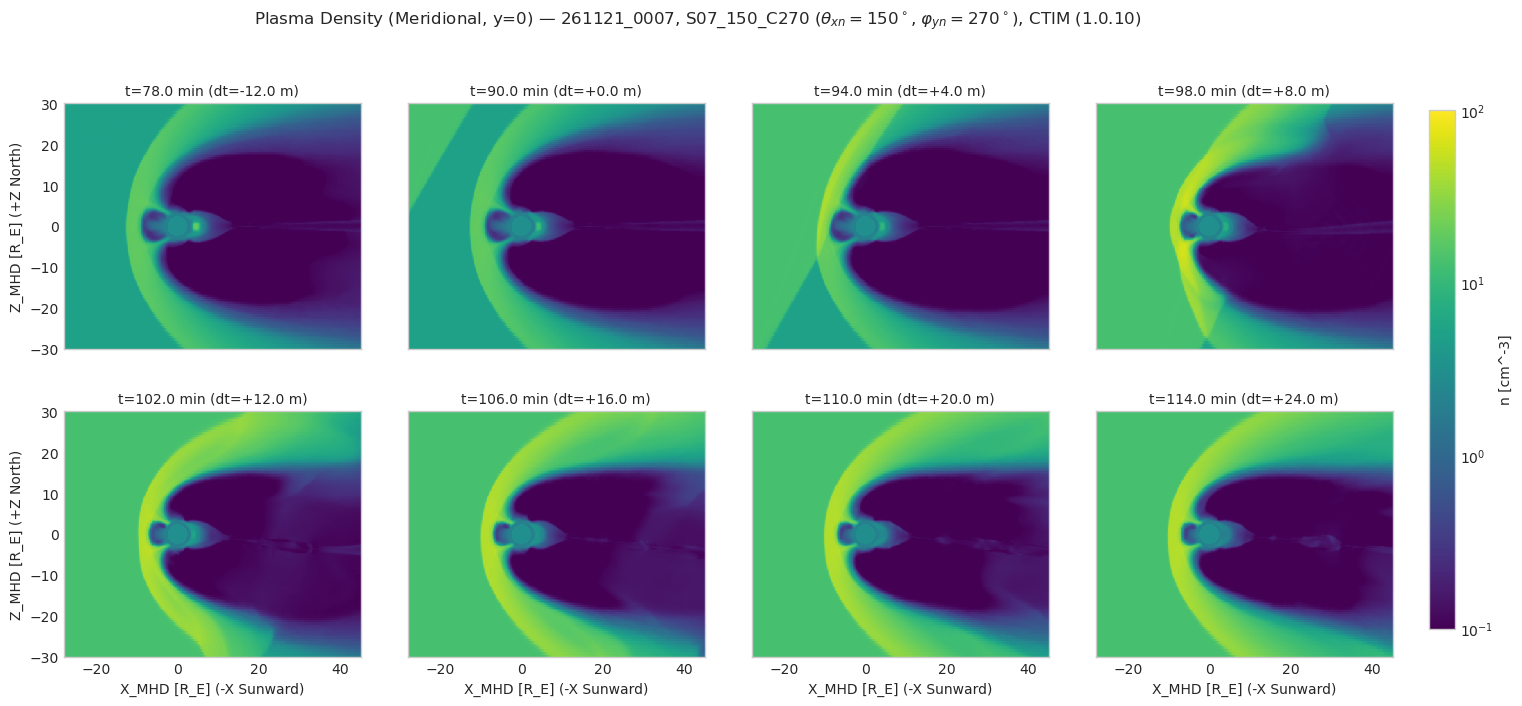

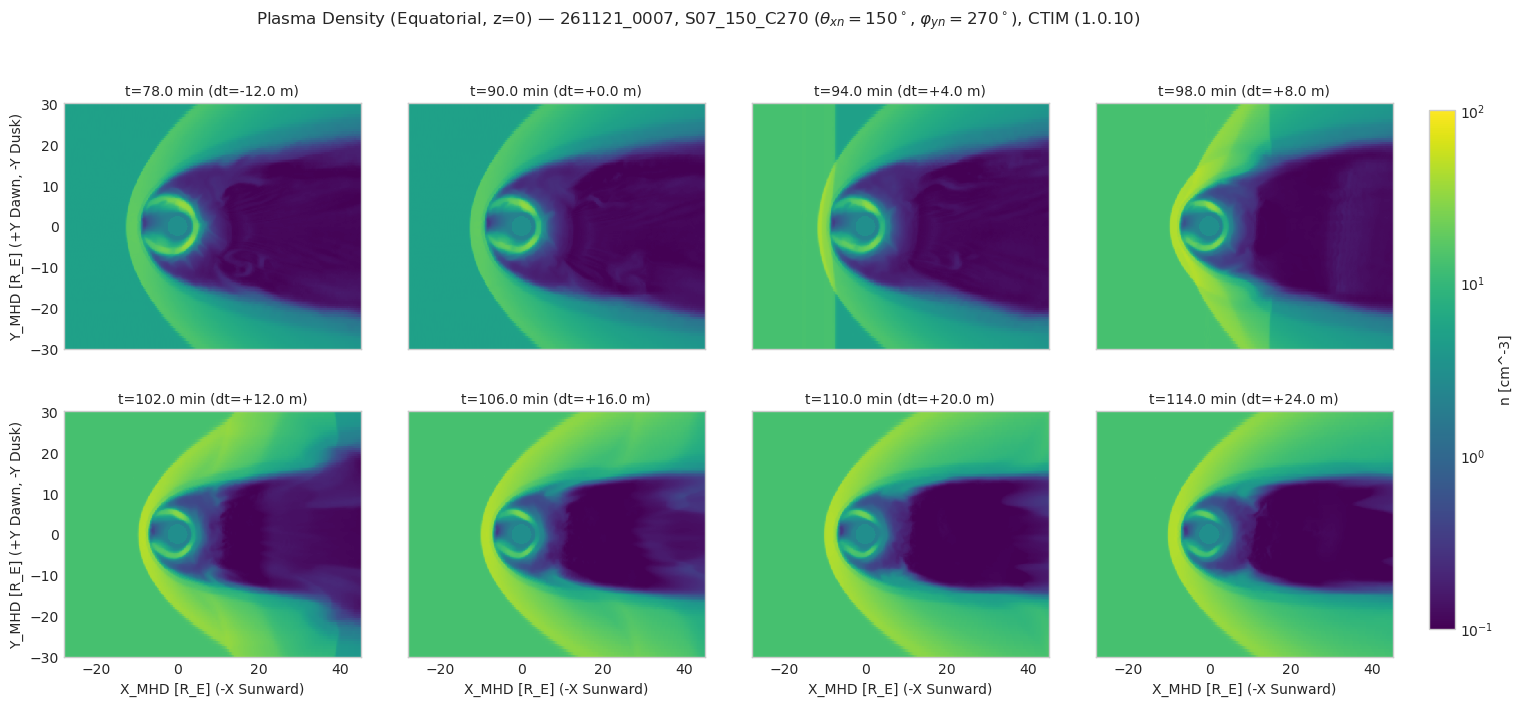

In [13]:
# Number density rr [cm^-3] in y=0 and z=0
plot_mhd_sequence(
    py_0.rr,
    mhd_snap_idx,
    "x",
    "z",
    slice(-28.0, 45.0),
    slice(-30.0, 30.0),
    title="Plasma Density (Meridional, y=0)",
    cbar_label="n [cm^-3]",
    norm=colors.LogNorm(vmin=1e-1, vmax=1e2),
    cmap="viridis",
    xlabel="X_MHD [R_E] (-X Sunward)",
    ylabel="Z_MHD [R_E] (+Z North)",
)

plot_mhd_sequence(
    pz_0.rr,
    mhd_snap_idx,
    "x",
    "y",
    slice(-28.0, 45.0),
    slice(-30.0, 30.0),
    title="Plasma Density (Equatorial, z=0)",
    cbar_label="n [cm^-3]",
    norm=colors.LogNorm(vmin=1e-1, vmax=1e2),
    cmap="viridis",
    xlabel="X_MHD [R_E] (-X Sunward)",
    ylabel="Y_MHD [R_E] (+Y Dawn, -Y Dusk)",
)

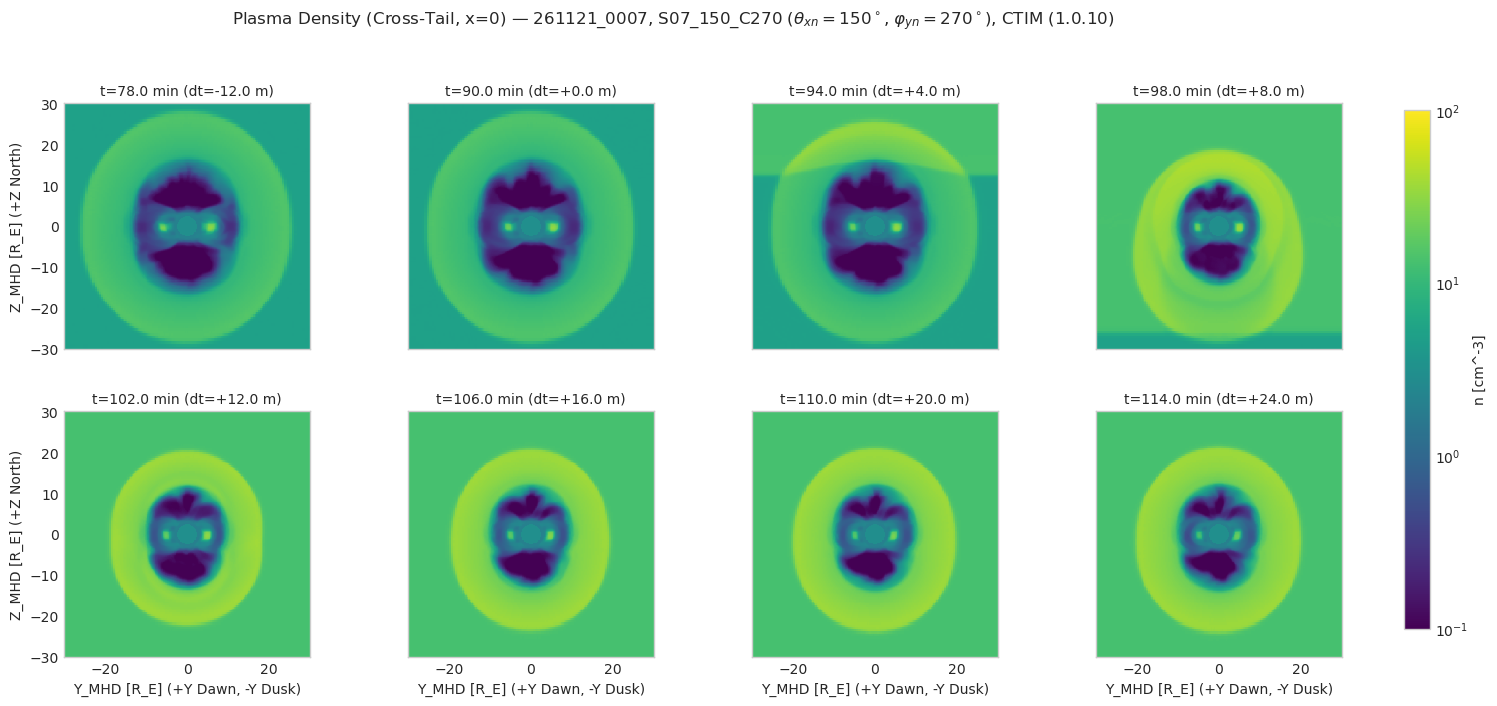

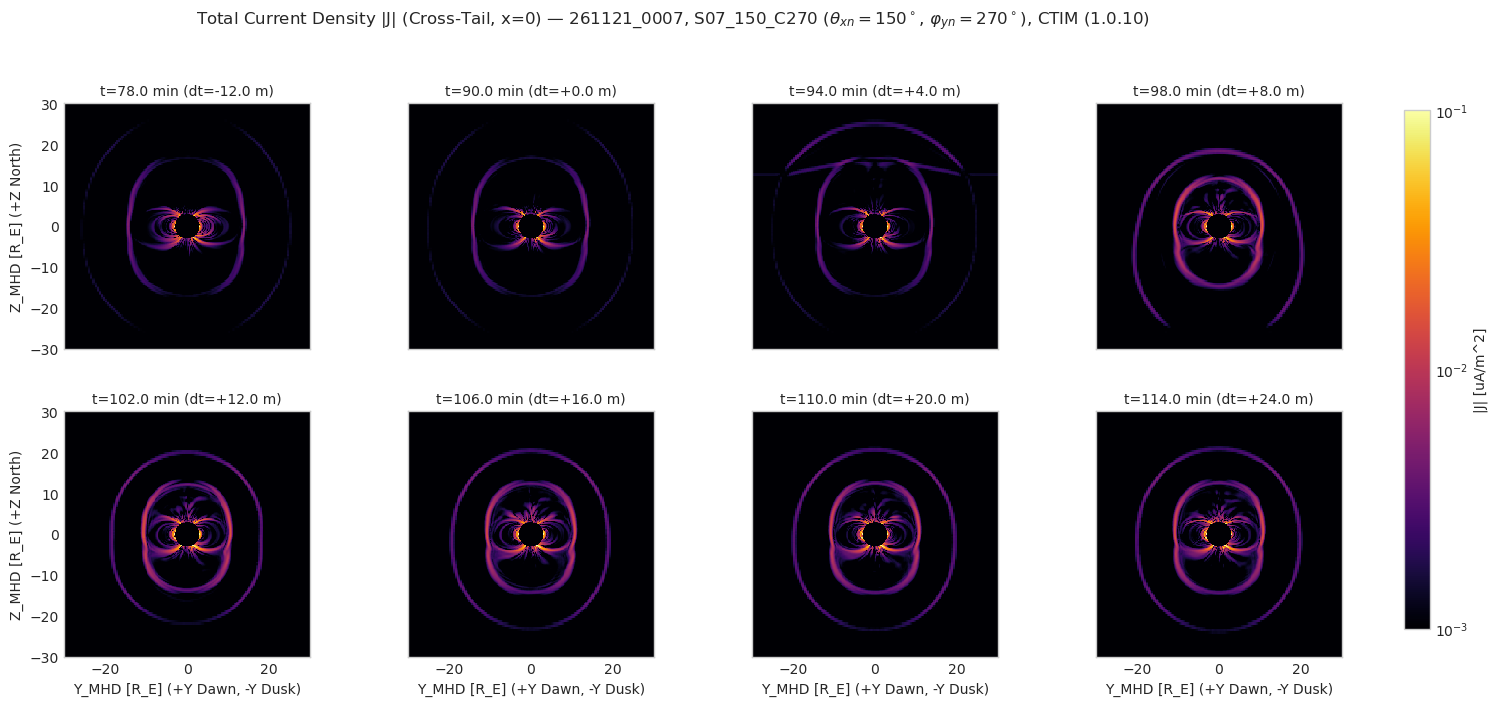

In [14]:
# Plasma density and total current density in x=0: Highlights the 3D clock-angle asymmetry
plot_mhd_sequence(
    px_0.rr,
    mhd_snap_idx,
    "y",
    "z",
    slice(-30.0, 30.0),
    slice(-30.0, 30.0),
    title="Plasma Density (Cross-Tail, x=0)",
    cbar_label="n [cm^-3]",
    norm=colors.LogNorm(vmin=1e-1, vmax=1e2),
    cmap="viridis",
    xlabel="Y_MHD [R_E] (+Y Dawn, -Y Dusk)",
    ylabel="Z_MHD [R_E] (+Z North)",
)

plot_mhd_sequence(
    xjtot_x,
    mhd_snap_idx,
    "y",
    "z",
    slice(-30.0, 30.0),
    slice(-30.0, 30.0),
    title="Total Current Density |J| (Cross-Tail, x=0)",
    cbar_label="|J| [uA/m^2]",
    norm=colors.LogNorm(vmin=1e-3, vmax=1e-1),
    cmap="inferno",
    xlabel="Y_MHD [R_E] (+Y Dawn, -Y Dusk)",
    ylabel="Z_MHD [R_E] (+Z North)",
)

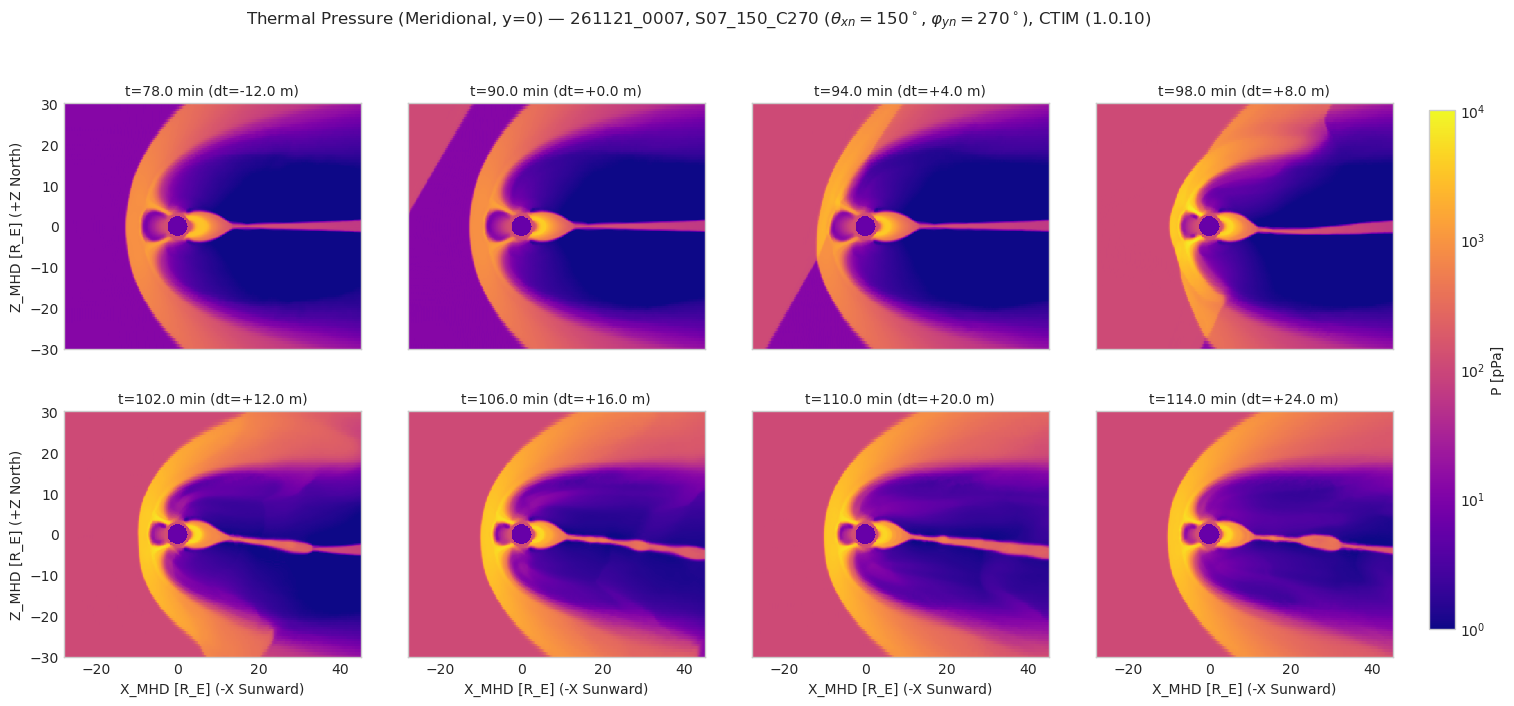

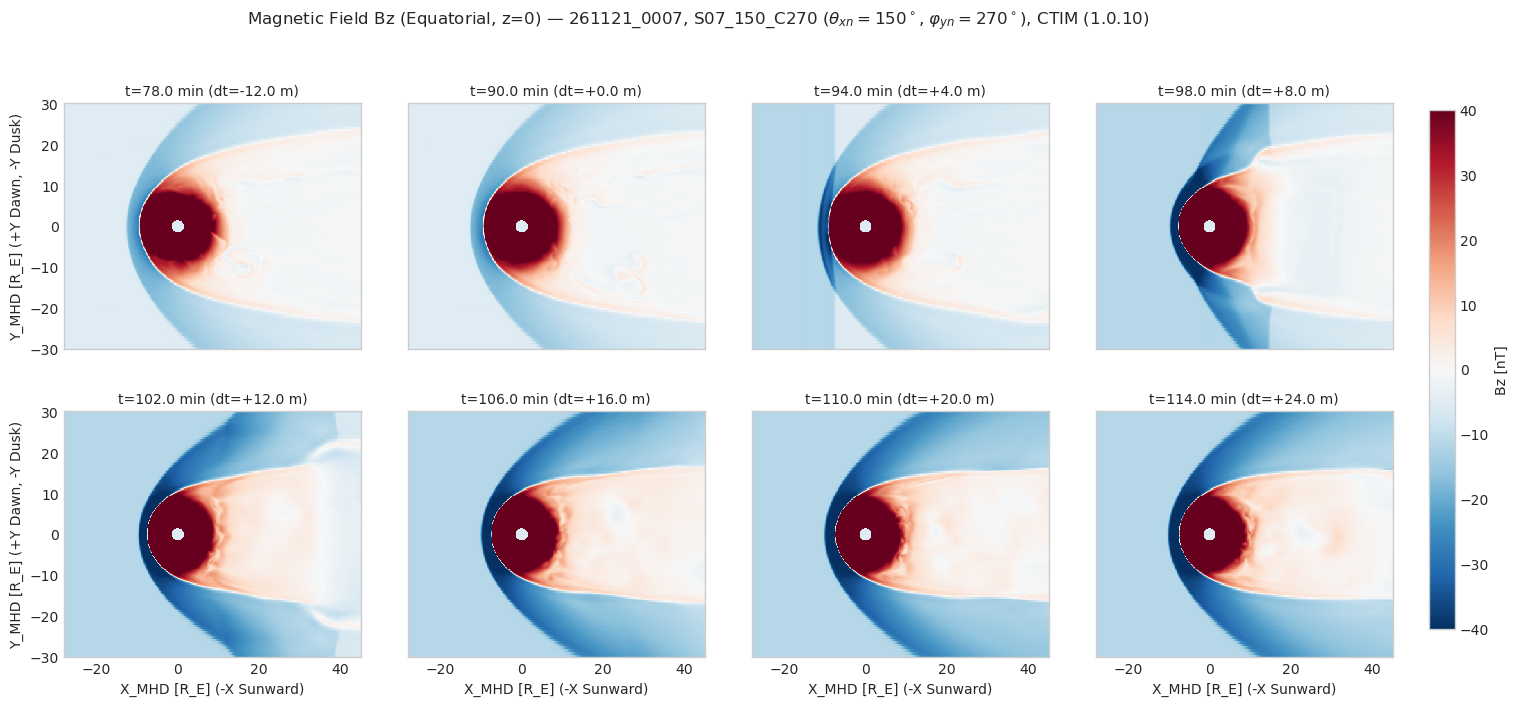

In [15]:
# Thermal pressure pp [pPa] and magnetic field Bz [nT] in y=0 and z=0
plot_mhd_sequence(
    py_0.pp,
    mhd_snap_idx,
    "x",
    "z",
    slice(-28.0, 45.0),
    slice(-30.0, 30.0),
    title="Thermal Pressure (Meridional, y=0)",
    cbar_label="P [pPa]",
    norm=colors.LogNorm(vmin=1e0, vmax=1e4),
    cmap="plasma",
    xlabel="X_MHD [R_E] (-X Sunward)",
    ylabel="Z_MHD [R_E] (+Z North)",
)

plot_mhd_sequence(
    pz_0.bz,
    mhd_snap_idx,
    "x",
    "y",
    slice(-28.0, 45.0),
    slice(-30.0, 30.0),
    title="Magnetic Field Bz (Equatorial, z=0)",
    cbar_label="Bz [nT]",
    cmap="RdBu_r",
    vmin=-40.0,
    vmax=40.0,
    xlabel="X_MHD [R_E] (-X Sunward)",
    ylabel="Y_MHD [R_E] (+Y Dawn, -Y Dusk)",
)

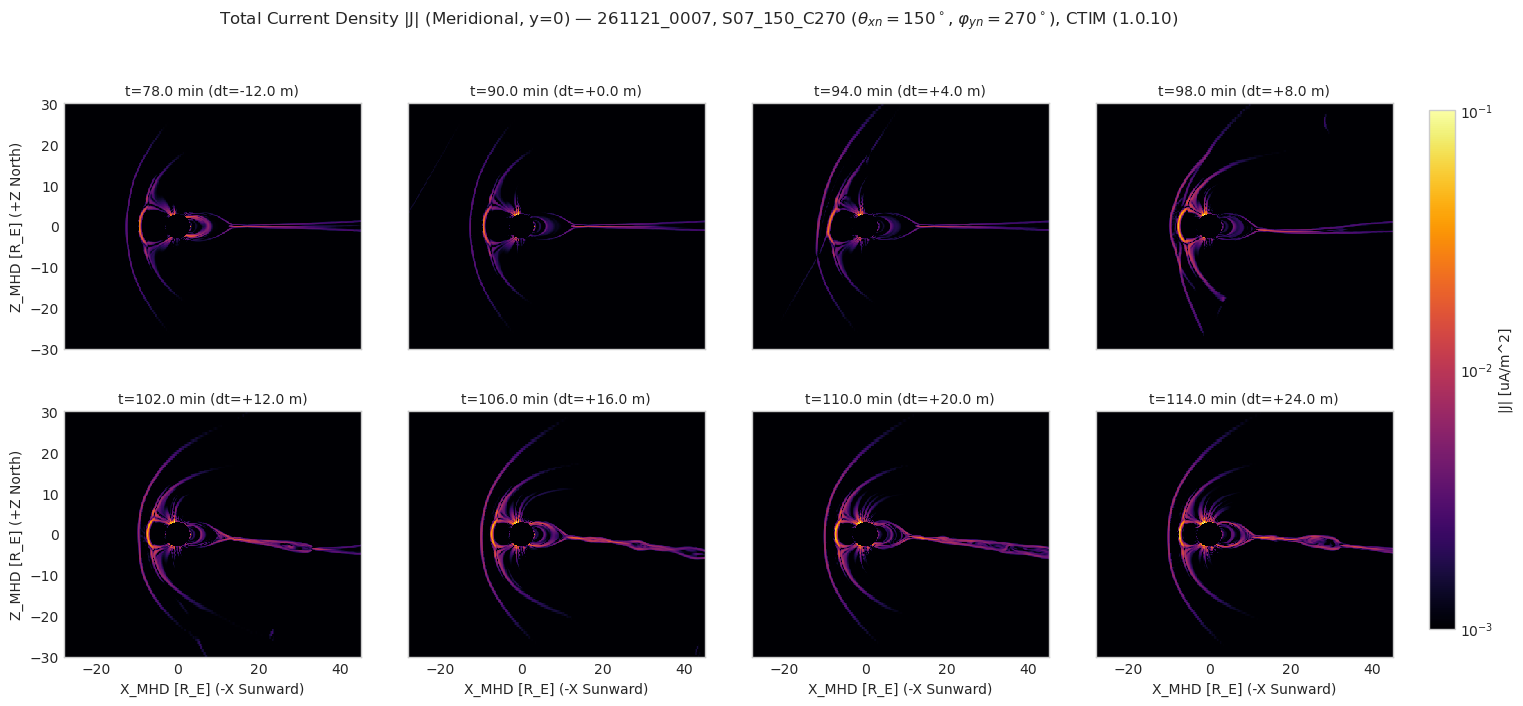

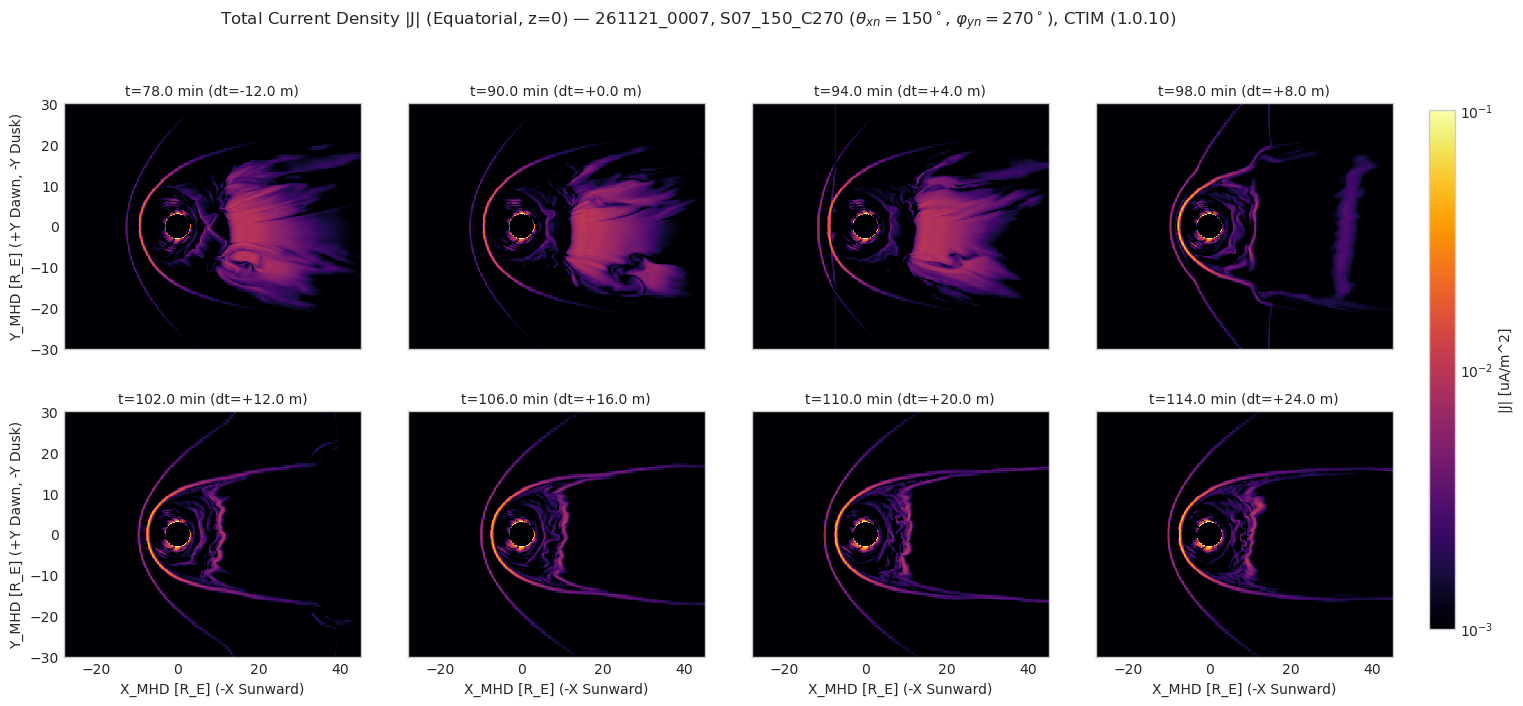

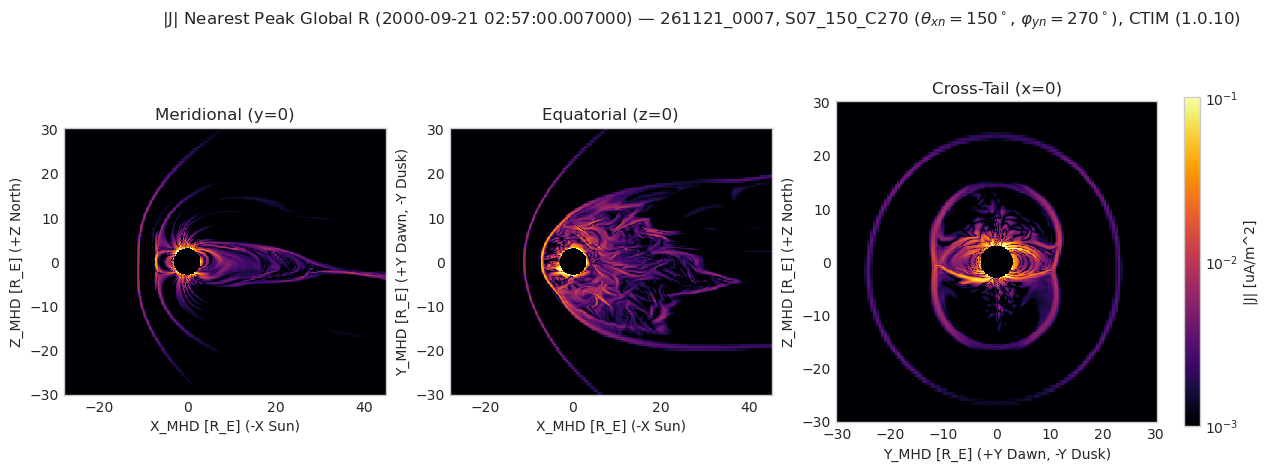

In [16]:
# Total current density sequence + 3-plane snapshot at peak global R.
plot_mhd_sequence(
    xjtot_y,
    mhd_snap_idx,
    "x",
    "z",
    slice(-28.0, 45.0),
    slice(-30.0, 30.0),
    title="Total Current Density |J| (Meridional, y=0)",
    cbar_label="|J| [uA/m^2]",
    norm=colors.LogNorm(vmin=1e-3, vmax=1e-1),
    cmap="inferno",
    xlabel="X_MHD [R_E] (-X Sunward)",
    ylabel="Z_MHD [R_E] (+Z North)",
)

plot_mhd_sequence(
    xjtot_z,
    mhd_snap_idx,
    "x",
    "y",
    slice(-28.0, 45.0),
    slice(-30.0, 30.0),
    title="Total Current Density |J| (Equatorial, z=0)",
    cbar_label="|J| [uA/m^2]",
    norm=colors.LogNorm(vmin=1e-3, vmax=1e-1),
    cmap="inferno",
    xlabel="X_MHD [R_E] (-X Sunward)",
    ylabel="Y_MHD [R_E] (+Y Dawn, -Y Dusk)",
)

# 3-plane snapshot nearest peak global NH R
t_mhd_peak = peak_R_nh["time"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
norm_j = colors.LogNorm(vmin=1e-3, vmax=1e-1)

specs_3p = [
    (
        xjtot_y.sel(time=t_mhd_peak, method="nearest").sel(
            x=slice(-28.0, 45.0), z=slice(-30.0, 30.0)
        ),
        "x",
        "z",
        "Meridional (y=0)",
        "X_MHD [R_E] (-X Sun)",
        "Z_MHD [R_E] (+Z North)",
    ),
    (
        xjtot_z.sel(time=t_mhd_peak, method="nearest").sel(
            x=slice(-28.0, 45.0), y=slice(-30.0, 30.0)
        ),
        "x",
        "y",
        "Equatorial (z=0)",
        "X_MHD [R_E] (-X Sun)",
        "Y_MHD [R_E] (+Y Dawn, -Y Dusk)",
    ),
    (
        xjtot_x.sel(time=t_mhd_peak, method="nearest").sel(
            y=slice(-30.0, 30.0), z=slice(-30.0, 30.0)
        ),
        "y",
        "z",
        "Cross-Tail (x=0)",
        "Y_MHD [R_E] (+Y Dawn, -Y Dusk)",
        "Z_MHD [R_E] (+Z North)",
    ),
]
for ax, (da_p, xd, yd, ttl, xl, yl) in zip(axes, specs_3p):
    arr = da_p.squeeze().transpose(yd, xd)
    pcm = ax.pcolormesh(
        arr.coords[xd].values,
        arr.coords[yd].values,
        arr.values,
        cmap="inferno",
        norm=norm_j,
        shading="auto",
    )
    ax.set_title(ttl)
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.set_aspect("equal", adjustable="box")

t_snap_actual = pd.Timestamp(xjtot_y.sel(time=t_mhd_peak, method="nearest").time.values)
fig.suptitle(f"|J| Nearest Peak Global R ({t_snap_actual}) — {RUN_LABEL}", fontsize=12)
fig.colorbar(pcm, ax=axes.ravel().tolist(), shrink=0.82, pad=0.02, label="|J| [uA/m^2]")
plt.show()

## 4. The Ionosphere Structure

Side-by-side NH (`50° to 90°`) and SH (`-90° to -50°`) polar maps in Solar Magnetic (SM) coordinates

In [17]:
# Helper for side-by-side NH & SH polar maps
def _draw_polar_ax(
    ax,
    da_2d: xr.DataArray,
    hemisphere: str,
    lat_edge: int = 50,
    spacing: int = 10,
    cmap: str = "RdBu_r",
    levels=None,
    extend: str = "both",
    coastlines: bool = False,
    stations: bool = False,
    highlight_station: str | None = None,
    peak_marker: bool = False,
):
    time_val = (
        np.datetime64(np.atleast_1d(da_2d.coords["time"].values)[0])
        if "time" in da_2d.coords
        else None
    )
    is_north = hemisphere == "north"
    lats_min, lats_max = (lat_edge, 90) if is_north else (-90, -lat_edge)
    lat_vals_all = da_2d.coords["lats"].values
    sl = (
        slice(lats_max, lats_min)
        if lat_vals_all[0] > lat_vals_all[-1]
        else slice(lats_min, lats_max)
    )
    sub = da_2d.sel(lats=sl).squeeze().transpose("lats", "longs")

    lat_v = sub.coords["lats"].values
    lon_v = sub.coords["longs"].values
    z_v = sub.values
    r_1d = 90.0 - lat_v if is_north else 90.0 + lat_v
    theta_grid, r_grid = np.meshgrid(np.deg2rad(lon_v), r_1d)

    mesh = ax.contourf(theta_grid, r_grid, z_v, cmap=cmap, levels=levels, extend=extend)

    if coastlines:
        plot_polar.draw_coastlines_polar(ax, lats_min, time=time_val)
    if stations and is_north:
        plot_polar.draw_magnetometers(
            ax, lats_min=lats_min, time=time_val, highlight=highlight_station
        )
    if peak_marker and np.any(np.isfinite(z_v)):
        iy, ix = np.unravel_index(int(np.nanargmax(np.abs(z_v))), z_v.shape)
        ax.scatter(
            np.deg2rad(lon_v[ix]),
            r_1d[iy],
            marker="*",
            s=110,
            color="lime",
            edgecolor="k",
            lw=0.7,
            zorder=8,
        )

    range_r, grids_r = plot_polar.get_plot_params(lats_max, lats_min, spacing)
    ax.set_thetagrids(np.arange(0, 360, 30), plot_polar.grids_theta_mlt, fontsize=8)
    ax.set_rgrids(range_r, grids_r, fontsize=8)
    plot_rmax = 90 - lat_edge
    ax.set_rmax(plot_rmax)
    ax.set_ylim(0, plot_rmax)
    ax.set_axisbelow(False)
    hemi_lbl = "North" if is_north else "South"
    ax.set_title(f"{hemi_lbl}", pad=10, fontsize=10.5)
    return mesh


def plot_polar_nh_sh(
    da_2d: xr.DataArray,
    title: str,
    cbar_label: str,
    cmap: str = "RdBu_r",
    levels=None,
    extend: str = "both",
    lat_edge: int = 50,
    spacing: int = 10,
    coastlines: bool = True,
    stations: bool = True,
    highlight_station: str | None = None,
    peak_marker: bool = False,
):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(11.5, 5.2),
        subplot_kw={"projection": "polar", "theta_offset": np.pi / 2},
    )
    m0 = _draw_polar_ax(
        axes[0],
        da_2d,
        "north",
        lat_edge=lat_edge,
        spacing=spacing,
        cmap=cmap,
        levels=levels,
        extend=extend,
        coastlines=coastlines,
        stations=stations,
        highlight_station=highlight_station,
        peak_marker=peak_marker,
    )
    _draw_polar_ax(
        axes[1],
        da_2d,
        "south",
        lat_edge=lat_edge,
        spacing=spacing,
        cmap=cmap,
        levels=levels,
        extend=extend,
        coastlines=coastlines,
        stations=False,
        peak_marker=peak_marker,
    )
    t_str = ""
    if "time" in da_2d.coords:
        ts = pd.Timestamp(np.atleast_1d(da_2d.coords["time"].values)[0])
        dt_m = (ts - SHOCK_TIME_TS).total_seconds() / 60.0
        t_str = f", {ts.strftime('%Y-%m-%d %H:%M:%S')} (dt_shock={dt_m:+.2f} min)"
    fig.suptitle(f"{title}{t_str}", fontsize=11.5, y=1.02)
    fig.subplots_adjust(wspace=0.22, right=0.88)
    cax = fig.add_axes([0.90, 0.14, 0.02, 0.72])
    fig.colorbar(m0, cax=cax, label=cbar_label)
    plt.show()


# Select key diagnostic timestamps from iof.
t_pre_target = START_TIME + pd.Timedelta(
    minutes=min(SHOCK_TIME_MIN - 12.0, iof_elapsed_min[-1])
)
t_pre = pd.Timestamp(iof.time.sel(time=t_pre_target, method="nearest").values)
t_peak_R_nh = peak_R_nh["time"]
t_peak_R_sh = peak_R_sh["time"]
t_peak_R_st = pd.Timestamp(station_max_sim_time)
t_peak_AL_nh = pd.Timestamp(al_grid_n.idxmin().values)

# Shared polar-map colorbar ceiling for R (99.9th auroral percentile, capped at 25 nT/s)
r_map_vmax = float(
    np.clip(
        np.ceil(np.nanpercentile(R_valid.where(np.abs(R_valid.lats) >= 50), 99.9)),
        6.0,
        25.0,
    )
)

print(f"t_pre: {t_pre} (dt={(t_pre - SHOCK_TIME_TS).total_seconds() / 60:+.2f} min)")
print(f"t_peak_R_nh: {t_peak_R_nh} (dt={peak_R_nh['dt_shock_min']:+.2f} min)")
print(f"t_peak_R_sh: {t_peak_R_sh} (dt={peak_R_sh['dt_shock_min']:+.2f} min)")
print(
    f"t_peak_R_st: {t_peak_R_st} ({station_max_sim_name}, dt={station_max_dt_shock:+.2f} min)"
)
print(
    f"t_peak_AL_nh: {t_peak_AL_nh} (dt={(t_peak_AL_nh - SHOCK_TIME_TS).total_seconds() / 60:+.2f} min)"
)
print(f"r_map_vmax: {r_map_vmax:.1f} nT/s (extend='max')")

t_pre: 2000-09-21 01:18:00.072000 (dt=-12.00 min)
t_peak_R_nh: 2000-09-21 02:57:00.007000 (dt=+87.00 min)
t_peak_R_sh: 2000-09-21 02:53:06.074000 (dt=+83.10 min)
t_peak_R_st: 2000-09-21 02:59:00.068000 (ABK, dt=+89.00 min)
t_peak_AL_nh: 2000-09-21 02:49:06.078000 (dt=+79.10 min)
r_map_vmax: 6.0 nT/s (extend='max')


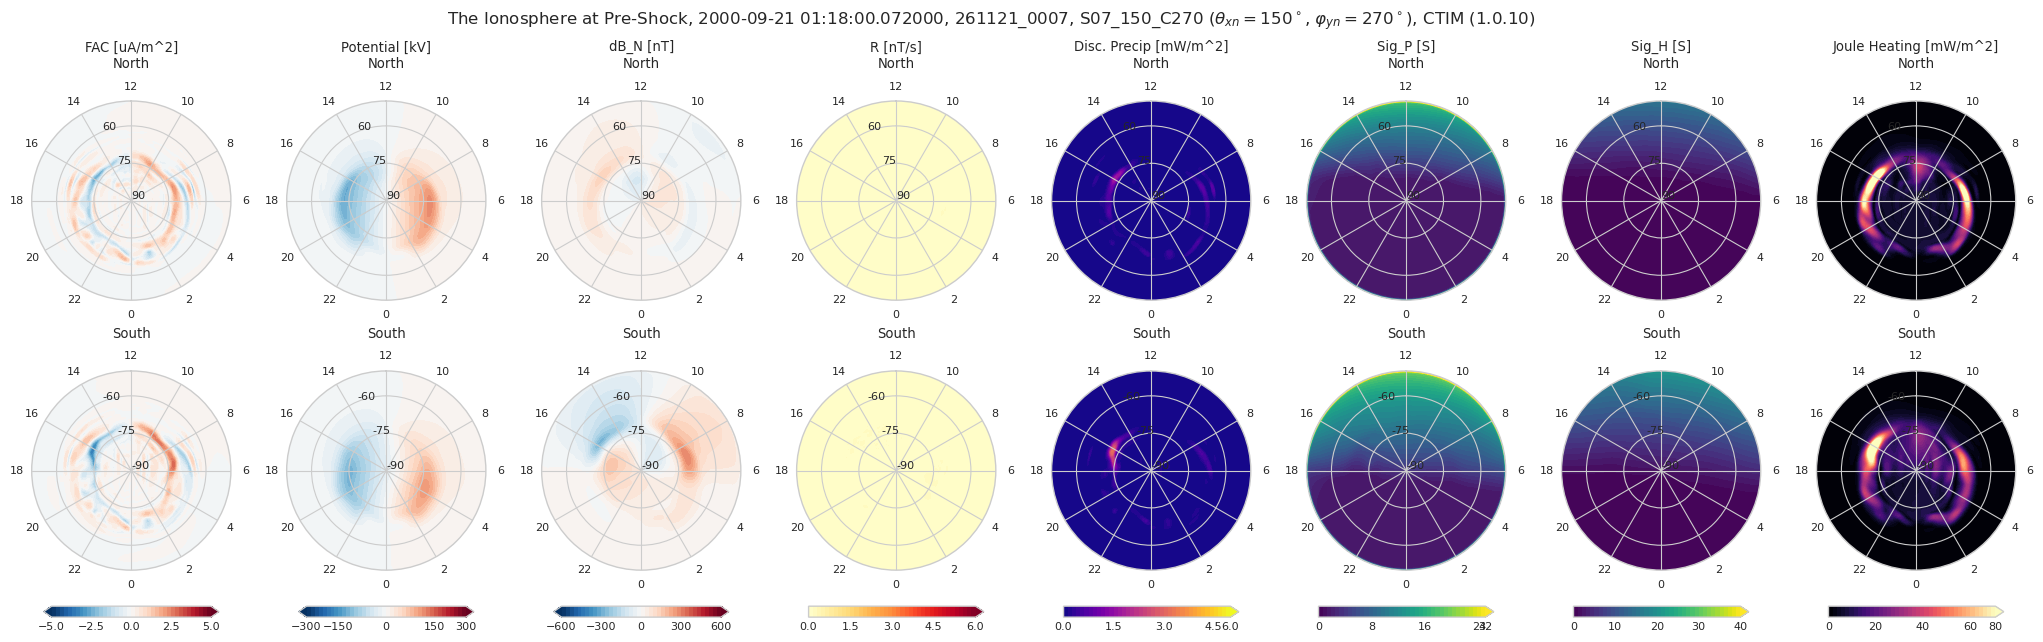

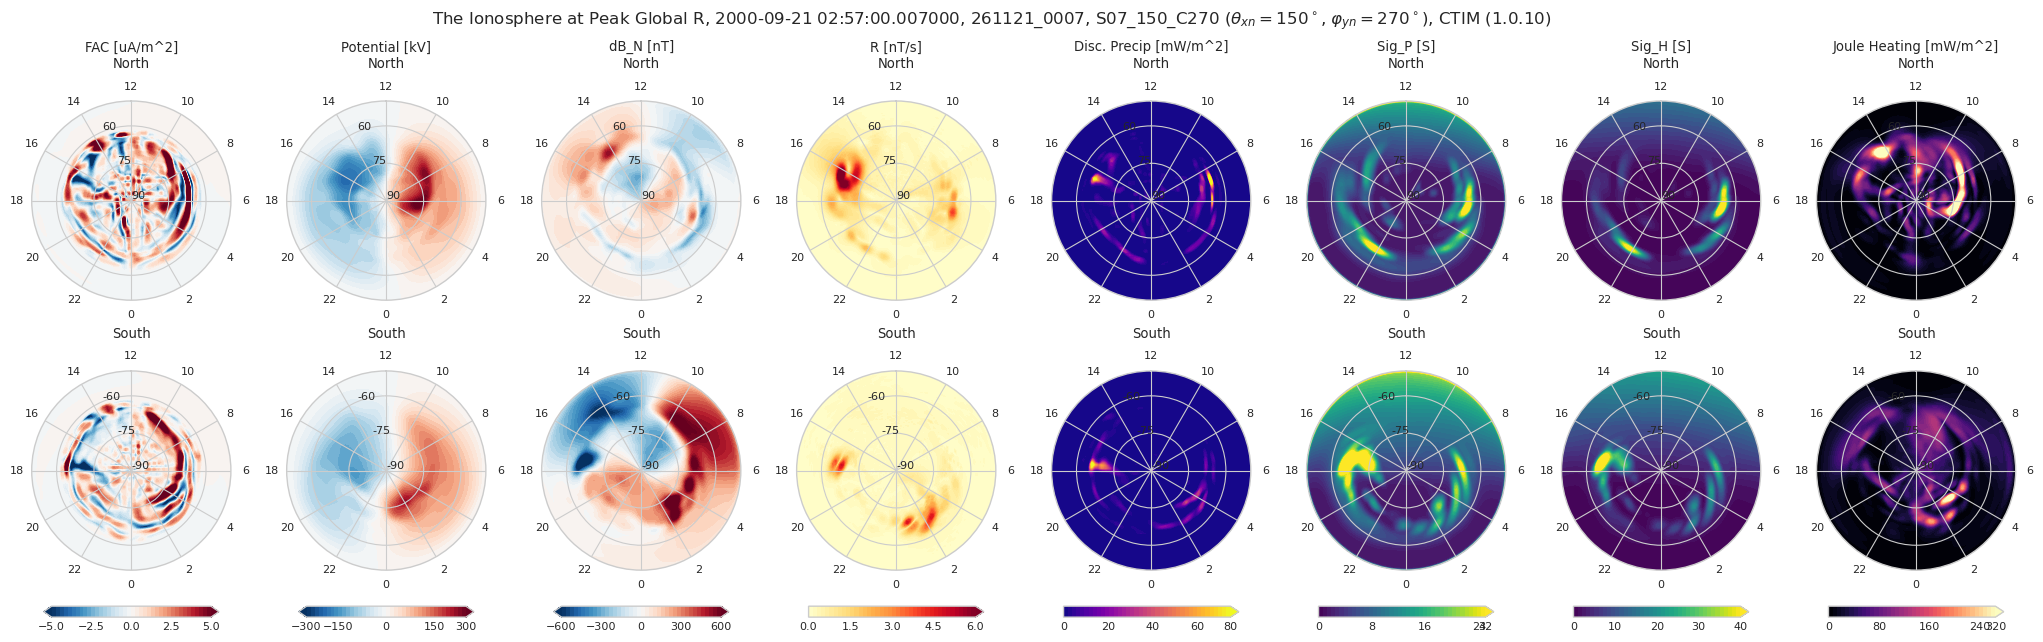

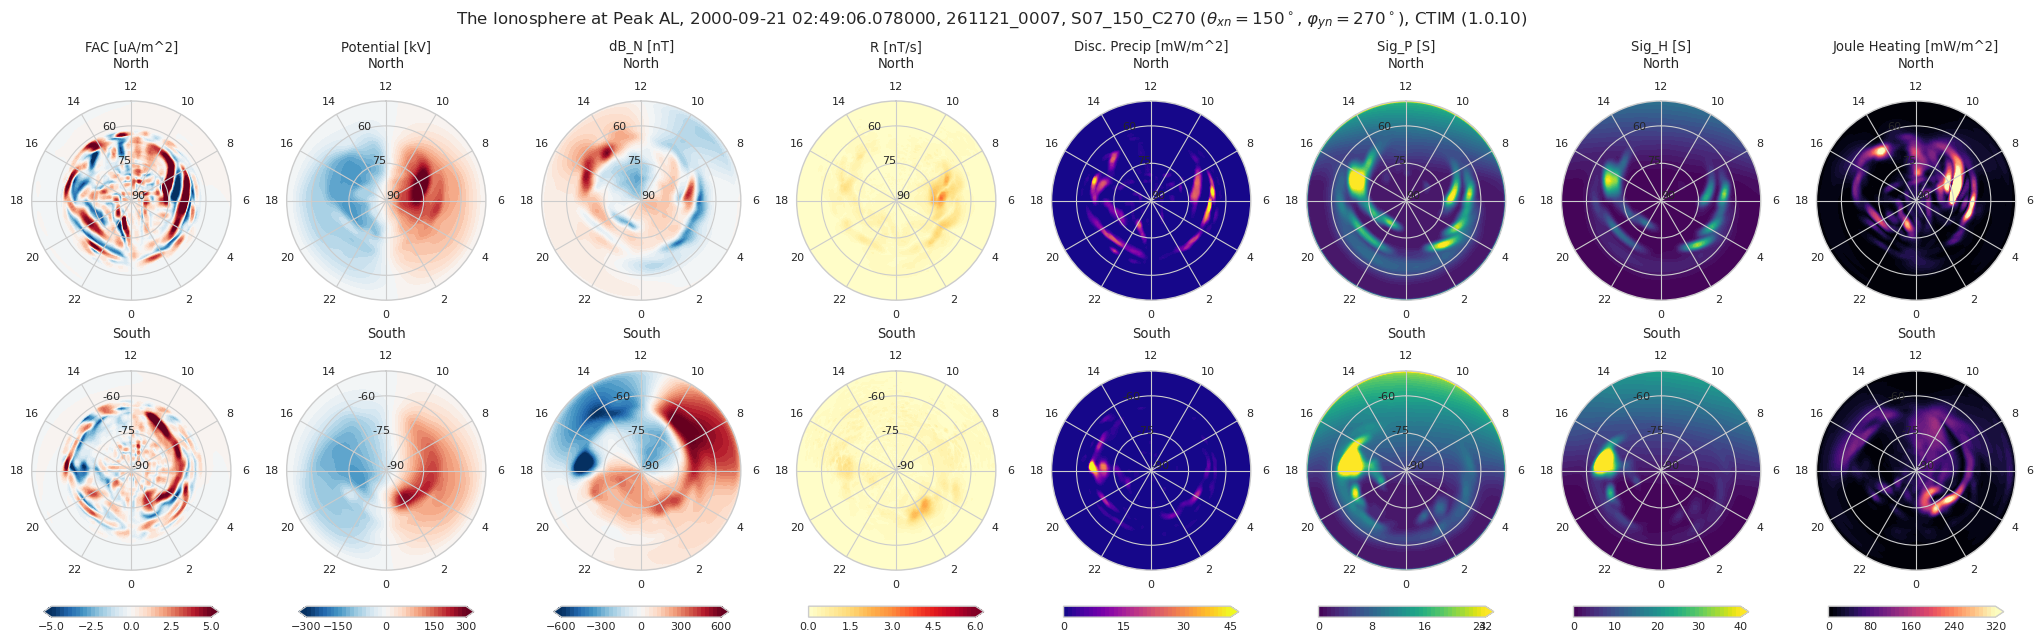

In [18]:
# Multi-variable overview at peak global NH R (NH on top row, SH on bottom row)
for label, ts in [
    ("Pre-Shock", t_pre),
    ("Peak Global R", t_peak_R_nh),
    ("Peak AL", t_peak_AL_nh),
]:
    iof_pk = iof.sel(time=ts).load()
    R_pk = delbh_t_sim.sel(time=ts)

    panel_specs = [
        (
            iof_pk["fac_tot"] * 1e6,
            "FAC [uA/m^2]",
            "RdBu_r",
            np.linspace(-5, 5, 41),
            "both",
        ),
        (
            iof_pk["pot"] * 1e-3,
            "Potential [kV]",
            "RdBu_r",
            np.linspace(-250, 250, 41),
            "both",
        ),
        (
            -iof_pk["delbt"] * 1e9,
            "dB_N [nT]",
            "RdBu_r",
            np.linspace(-600, 600, 41),
            "both",
        ),
        (R_pk, "R [nT/s]", "YlOrRd", np.linspace(0, r_map_vmax, 41), "max"),
        (
            iof_pk["prec_e_fe_2"] * 1e3,
            "Disc. Precip [mW/m^2]",
            "plasma",
            np.linspace(
                0,
                max(
                    5.0,
                    float(
                        np.nanpercentile(
                            iof_pk["prec_e_fe_2"].where(np.abs(iof_pk.lats) >= 50), 99.5
                        )
                    )
                    * 1e3,
                ),
                41,
            ),
            "max",
        ),
        (iof_pk["sigp"], "Sig_P [S]", "viridis", np.linspace(0, 25, 41), "max"),
        (iof_pk["sigh"], "Sig_H [S]", "viridis", np.linspace(0, 40, 41), "max"),
        (
            iof_pk["xjh"] * 1e3,
            "Joule Heating [mW/m^2]",
            "magma",
            np.linspace(
                0,
                max(
                    50.0,
                    float(
                        np.nanpercentile(
                            iof_pk["xjh"].where(np.abs(iof_pk.lats) >= 50), 99.5
                        )
                    )
                    * 1e3,
                ),
                41,
            ),
            "max",
        ),
    ]

    fig, axes = plt.subplots(
        2,
        len(panel_specs),
        figsize=(3.2 * len(panel_specs), 7.8),
        subplot_kw={"projection": "polar", "theta_offset": np.pi / 2},
    )
    fig.subplots_adjust(hspace=0.32, wspace=0.28)
    for col_i, (da_v, lbl, cmap, lvls, ext) in enumerate(panel_specs):
        m_n = _draw_polar_ax(
            axes[0, col_i],
            da_v,
            "north",
            lat_edge=50,
            spacing=15,
            cmap=cmap,
            levels=lvls,
            extend=ext,
            coastlines=False,
            stations=False,
            peak_marker=False,
        )
        _draw_polar_ax(
            axes[1, col_i],
            da_v,
            "south",
            lat_edge=50,
            spacing=15,
            cmap=cmap,
            levels=lvls,
            extend=ext,
            coastlines=False,
            stations=False,
            peak_marker=False,
        )
        axes[0, col_i].set_title(f"{lbl}\nNorth", fontsize=9.5, pad=10)
        axes[1, col_i].set_title("South", fontsize=9.5, pad=10)
        cbar = fig.colorbar(
            m_n,
            ax=axes[:, col_i].tolist(),
            orientation="horizontal",
            pad=0.06,
            shrink=0.88,
            aspect=16,
        )
        cbar.locator = plt.MaxNLocator(nbins=4)
        cbar.update_ticks()
        cbar.ax.tick_params(labelsize=8)

    fig.suptitle(
        f"The Ionosphere at {label}, {ts}, {RUN_LABEL}",
        fontsize=12,
        y=0.99,
    )
    plt.show()

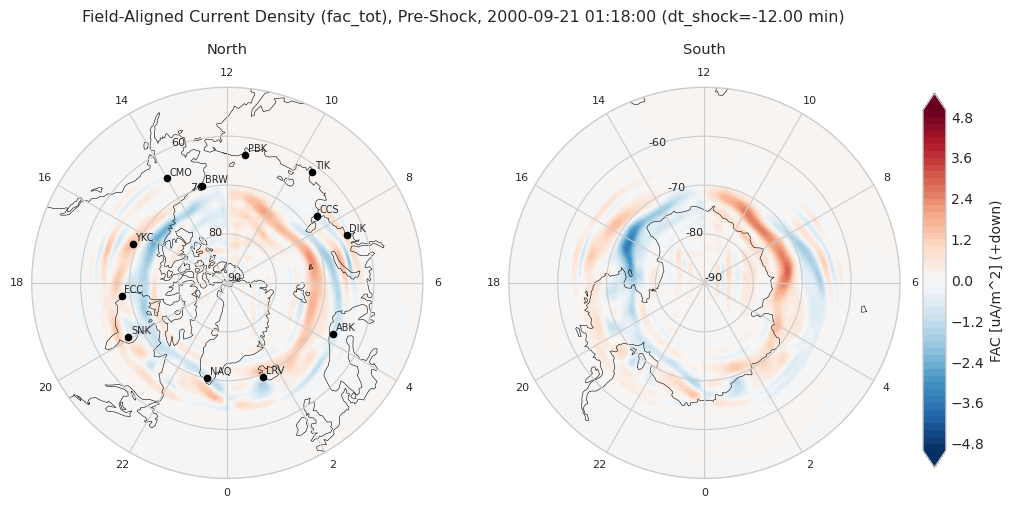

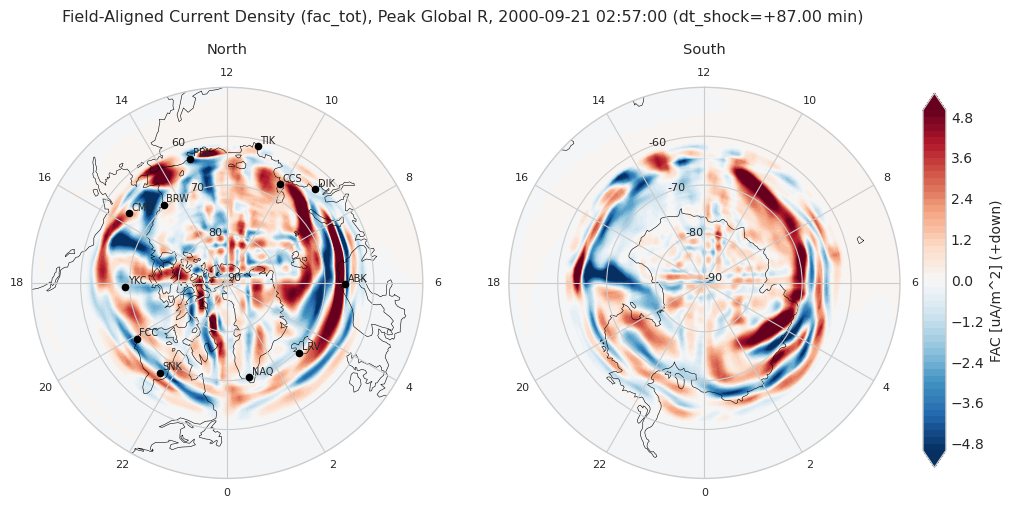

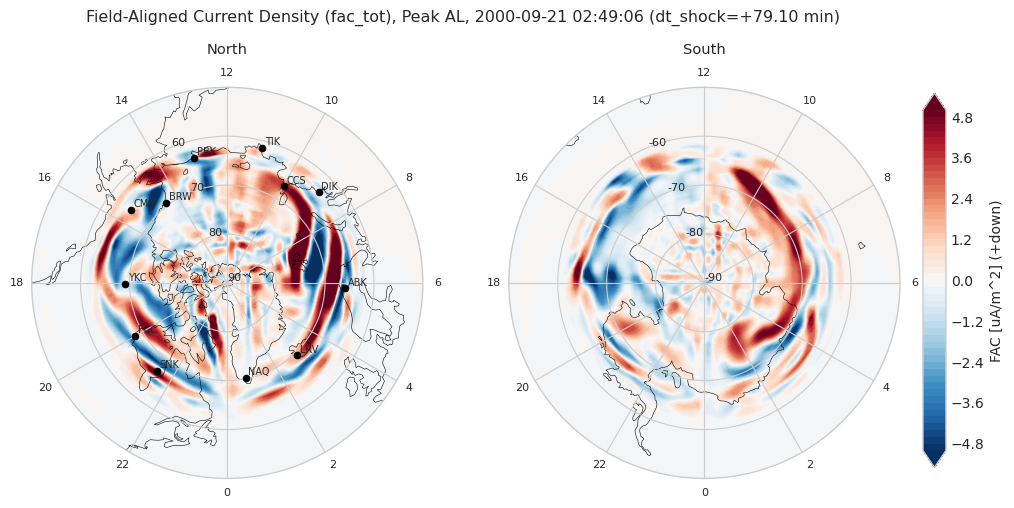

In [19]:
# Field-Aligned Current Density (fac_tot [uA/m^2])
fac_uA = iof_core["fac_tot"] * 1e6
levels_fac = np.linspace(-5.0, 5.0, 51)

for lbl, ts in [
    ("Pre-Shock", t_pre),
    ("Peak Global R", t_peak_R_nh),
    ("Peak AL", t_peak_AL_nh),
]:
    plot_polar_nh_sh(
        fac_uA.sel(time=ts),
        title=f"Field-Aligned Current Density (fac_tot), {lbl}",
        cbar_label="FAC [uA/m^2] (+down)",
        cmap="RdBu_r",
        levels=levels_fac,
        extend="both",
        coastlines=True,
        stations=True,
    )

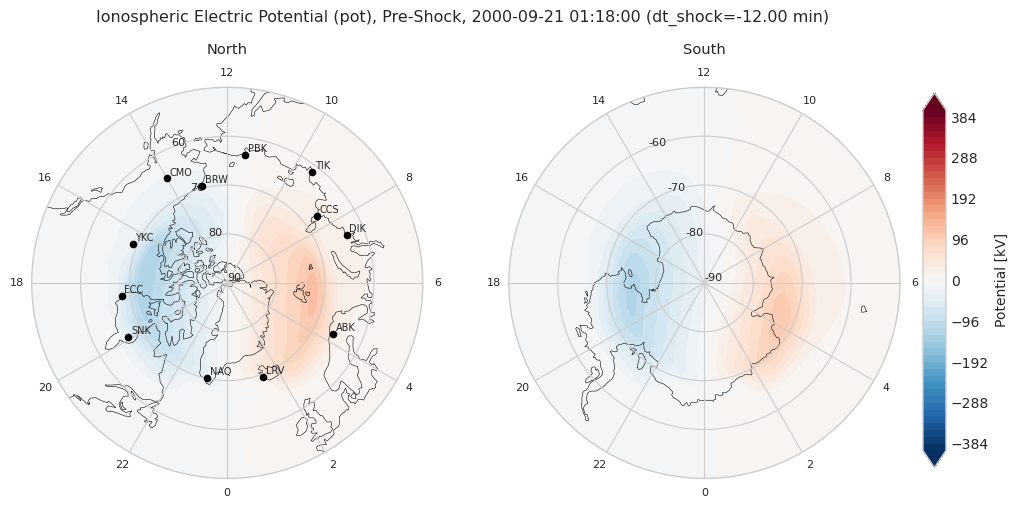

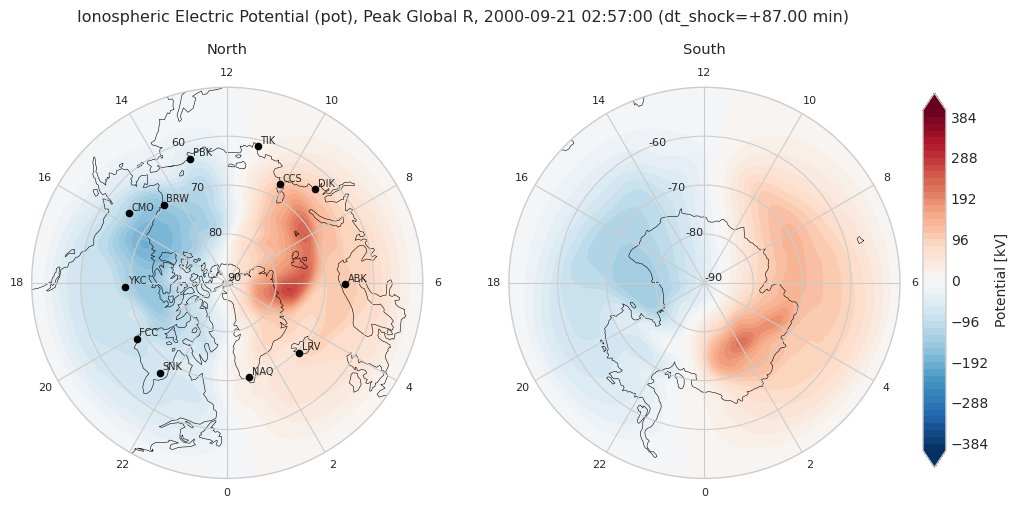

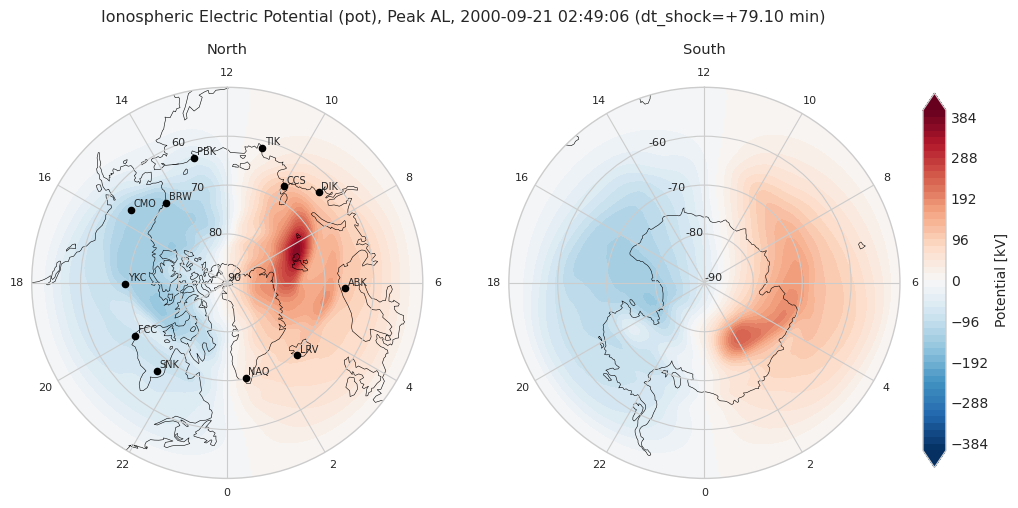

In [20]:
# Ionospheric Potential (pot [kV])
pot_kV = iof_core["pot"] * 1e-3
pot_abs = max(
    150.0,
    float(np.ceil(np.abs(pot_kV.where(np.abs(pot_kV.lats) >= 50)).max() / 50.0) * 50.0),
)
levels_pot = np.linspace(-pot_abs, pot_abs, 51)

for lbl, ts in [
    ("Pre-Shock", t_pre),
    ("Peak Global R", t_peak_R_nh),
    ("Peak AL", t_peak_AL_nh),
]:
    plot_polar_nh_sh(
        pot_kV.sel(time=ts),
        title=f"Ionospheric Electric Potential (pot), {lbl}",
        cbar_label="Potential [kV]",
        cmap="RdBu_r",
        levels=levels_pot,
        extend="both",
        coastlines=True,
        stations=True,
    )

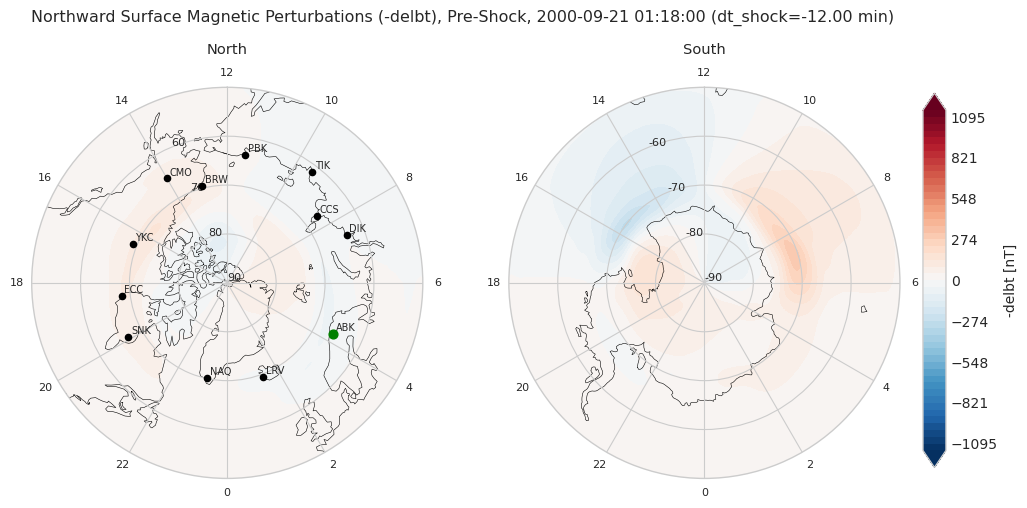

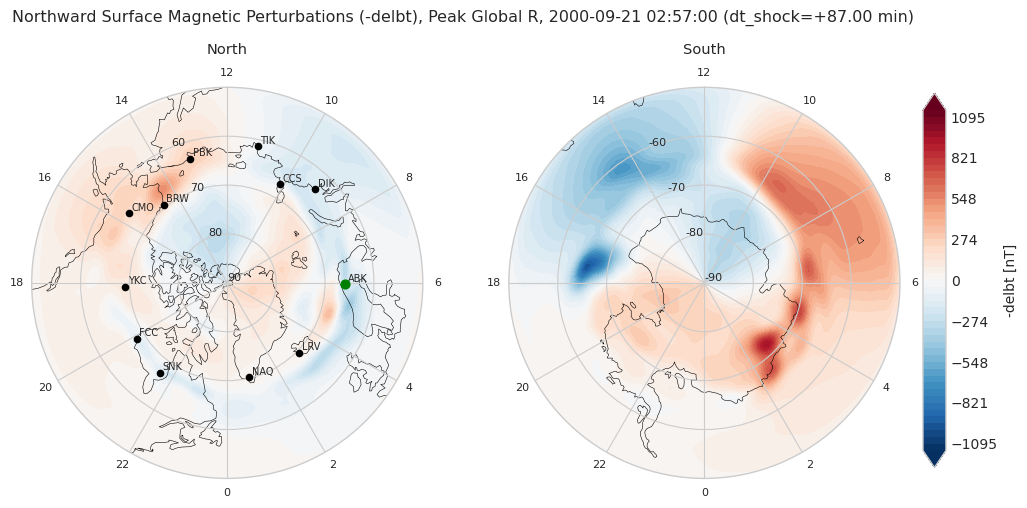

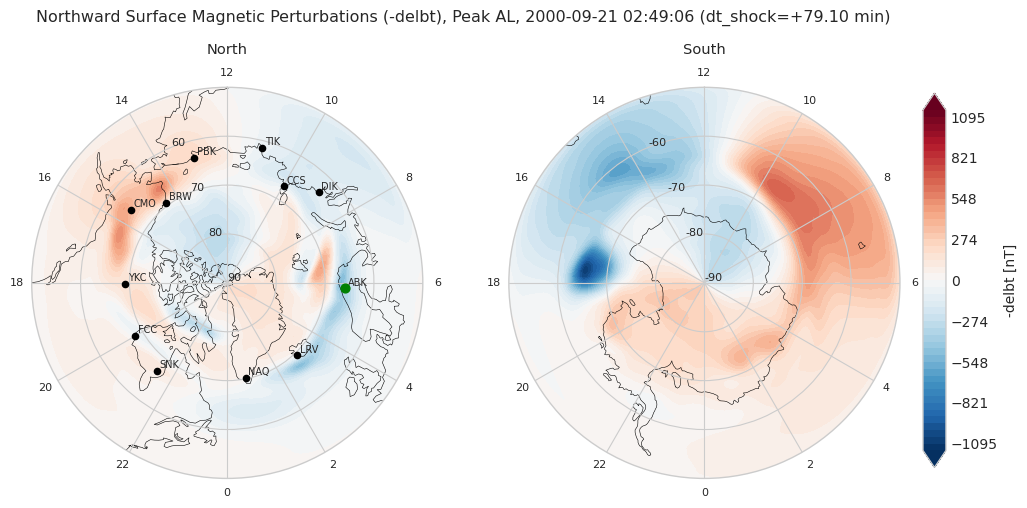

In [21]:
# Northward surface magnetic perturbations (-delbt [nT])
delbt_nT = iof_core["delbt"] * 1e9
abs_delbt = max(200.0, float(np.abs(delbt_nT.where(np.abs(delbt_nT.lats) >= 50)).max()))
levels_delbt = np.linspace(-abs_delbt, abs_delbt, 51)

for lbl, ts in [
    ("Pre-Shock", t_pre),
    ("Peak Global R", t_peak_R_nh),
    ("Peak AL", t_peak_AL_nh),
]:
    cur_al_stn = str(ggcm_al["ggcm.al_station"].sel(time=ts).item())
    plot_polar_nh_sh(
        -delbt_nT.sel(time=ts),
        title=f"Northward Surface Magnetic Perturbations (-delbt), {lbl}",
        cbar_label="-delbt [nT]",
        cmap="RdBu_r",
        levels=levels_delbt,
        extend="both",
        coastlines=True,
        stations=True,
        highlight_station=cur_al_stn,
    )

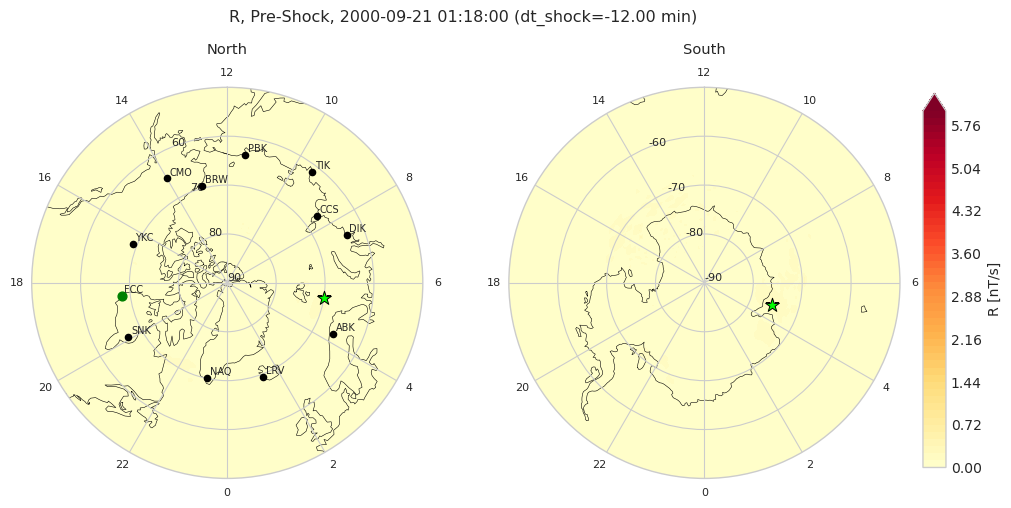

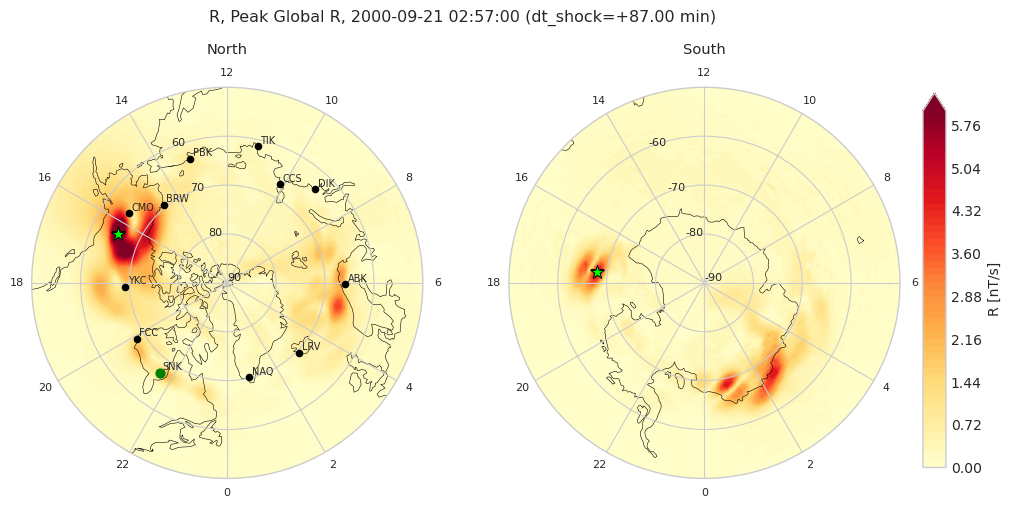

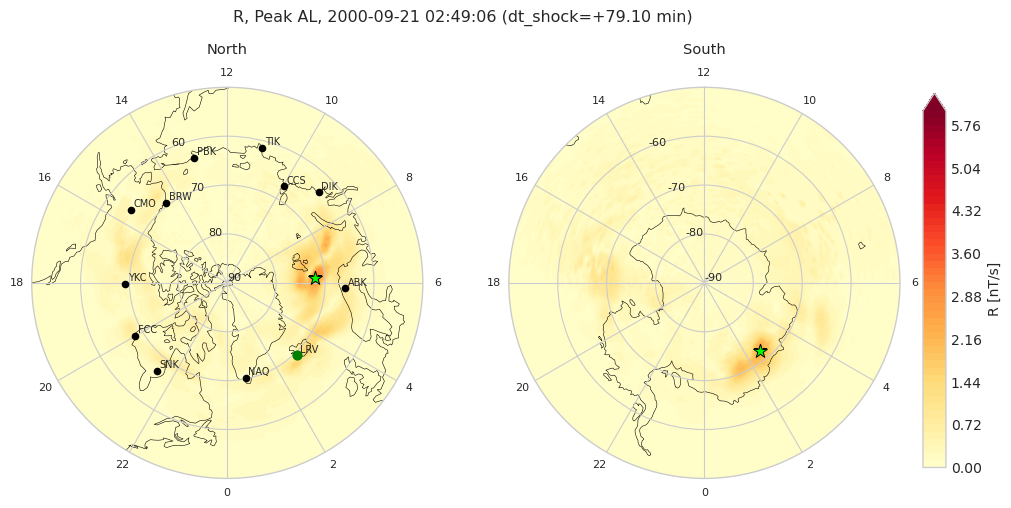

In [22]:
# R [nT/s]
levels_r = np.linspace(0.0, r_map_vmax, 51)

for lbl, ts in [
    ("Pre-Shock", t_pre),
    ("Peak Global R", t_peak_R_nh),
    ("Peak AL", t_peak_AL_nh),
]:
    st_cur = str(delbh_t_sim_station.sel(time=ts).idxmax(dim="station").item())
    plot_polar_nh_sh(
        delbh_t_sim.sel(time=ts),
        title=f"R, {lbl}",
        cbar_label="R [nT/s]",
        cmap="YlOrRd",
        levels=levels_r,
        extend="max",
        coastlines=True,
        stations=True,
        highlight_station=st_cur,
        peak_marker=True,
    )

## 5. Video Frame Export

Set `GENERATE_VIDEO_FRAMES = True` in the configuration cell at the top when ready to export PNG frames.

In [23]:
# Export magnetosphere density and total current density frames.
if GENERATE_VIDEO_FRAMES:
    out_rr = PLOTS_DIR / "figs_mag_rr"
    out_j = PLOTS_DIR / "figs_mag_xjtot"
    out_rr.mkdir(parents=True, exist_ok=True)
    out_j.mkdir(parents=True, exist_ok=True)

    for i in range(n_mhd):
        timestamp = py_0.time.values[i]
        time_str = np.datetime_as_string(timestamp, unit="s").replace(":", "")
        dt_m = mhd_dt_shock_min[i]

        # 1. Density
        fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(12, 14))
        py_0.rr.sel(x=slice(-28.0, 50.0), z=slice(-30.0, 30.0)).isel(time=i).T.plot(
            ax=ax1,
            vmin=1e-1,
            vmax=1e2,
            norm=colors.LogNorm(),
            cmap="viridis",
            extend="neither",
        )
        ax1.set_title(
            f"Density (y=0), t={mhd_elapsed_min[i]:.1f} min (dt_shock={dt_m:+.1f} min)"
        )
        pz_0.rr.sel(x=slice(-28.0, 50.0), y=slice(-30.0, 30.0)).isel(time=i).T.plot(
            ax=ax2,
            vmin=1e-1,
            vmax=1e2,
            norm=colors.LogNorm(),
            cmap="viridis",
            extend="neither",
        )
        ax2.set_title("Density (z=0) [+Y Dawn, -Y Dusk]")
        plt.tight_layout()
        fig.savefig(out_rr / f"rr_frame_{time_str}.png", dpi=200)
        plt.close(fig)

        # 2. Total current density
        fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(12, 14))
        xjtot_y.sel(x=slice(-28.0, 50.0), z=slice(-30.0, 30.0)).isel(time=i).T.plot(
            ax=ax1,
            vmin=1e-3,
            vmax=1e-1,
            norm=colors.LogNorm(),
            cmap="inferno",
            extend="neither",
        )
        ax1.set_title(
            f"|J| (y=0), t={mhd_elapsed_min[i]:.1f} min (dt_shock={dt_m:+.1f} min)"
        )
        xjtot_z.sel(x=slice(-28.0, 50.0), y=slice(-30.0, 30.0)).isel(time=i).T.plot(
            ax=ax2,
            vmin=1e-3,
            vmax=1e-1,
            norm=colors.LogNorm(),
            cmap="inferno",
            extend="neither",
        )
        ax2.set_title("|J| (z=0) [+Y Dawn, -Y Dusk]")
        plt.tight_layout()
        fig.savefig(out_j / f"xjtot_frame_{time_str}.png", dpi=200)
        plt.close(fig)

    print(f"Exported {n_mhd} magnetosphere frames each to {out_rr} and {out_j}.")
else:
    print("GENERATE_VIDEO_FRAMES is False — skipping magnetosphere frame export.")

Exported 179 magnetosphere frames each to /mnt/home/germaschewski/cu1010/runs/261121_0007/plots/figs_mag_rr and /mnt/home/germaschewski/cu1010/runs/261121_0007/plots/figs_mag_xjtot.


In [24]:
# Export ionosphere R frames across VIDEO_IONO_WINDOW_MIN.
if GENERATE_VIDEO_FRAMES:
    out_r = PLOTS_DIR / "figs_iono_R"
    out_r.mkdir(parents=True, exist_ok=True)

    if VIDEO_IONO_WINDOW_MIN is not None:
        w0, w1 = VIDEO_IONO_WINDOW_MIN
        iono_frame_indices = [
            i
            for i in range(1, n_iof, VIDEO_IONO_STRIDE)
            if w0 <= iof_elapsed_min[i] <= w1
        ]
    else:
        iono_frame_indices = list(range(1, n_iof, VIDEO_IONO_STRIDE))

    r_vid_levels = np.linspace(0.0, r_map_vmax, 51)

    for i in iono_frame_indices:
        st_cur = str(delbh_t_sim_station.isel(time=i).idxmax(dim="station").item())
        fig, axes = plt.subplots(
            1,
            2,
            figsize=(11.5, 5.2),
            subplot_kw={"projection": "polar", "theta_offset": np.pi / 2},
        )
        da_i = delbh_t_sim.isel(time=i)
        m0 = _draw_polar_ax(
            axes[0],
            da_i,
            "north",
            lat_edge=50,
            spacing=10,
            cmap="YlOrRd",
            levels=r_vid_levels,
            extend="max",
            coastlines=True,
            stations=True,
            highlight_station=st_cur,
            peak_marker=True,
        )
        _draw_polar_ax(
            axes[1],
            da_i,
            "south",
            lat_edge=50,
            spacing=10,
            cmap="YlOrRd",
            levels=r_vid_levels,
            extend="max",
            coastlines=True,
            stations=False,
            peak_marker=True,
        )
        timestamp = delbh_t_sim.time.values[i]
        ts_pd = pd.Timestamp(timestamp)
        time_str = np.datetime_as_string(timestamp, unit="s").replace(":", "")
        fig.suptitle(
            f"R, {ts_pd.strftime('%Y-%m-%d %H:%M:%S')} "
            f"(dt_shock={iof_dt_shock_min[i]:+.2f} min)",
            fontsize=11.5,
            y=0.99,
        )
        fig.subplots_adjust(wspace=0.22, right=0.88)
        cax = fig.add_axes([0.90, 0.14, 0.02, 0.72])
        fig.colorbar(m0, cax=cax, label="R [nT/s]")
        fig.savefig(out_r / f"R_frame_{time_str}.png", dpi=200)
        plt.close(fig)

    print(f"Exported {len(iono_frame_indices)} ionosphere R frames to {out_r}.")
else:
    print("GENERATE_VIDEO_FRAMES is False — skipping ionosphere R frame export.")

Exported 700 ionosphere R frames to /mnt/home/germaschewski/cu1010/runs/261121_0007/plots/figs_iono_R.
